---
title: "o-Xylene to phthalic anhydride: the classic hot spot"
description: "Froment's 1967 demonstration that effective kinetics plus a two-dimensional pseudo-homogeneous model reproduces fixed-bed hot spots: both models rebuilt, and the disagreement between their runaway limits measured continuously."
categories: [sec:C, struct:S2, struct:S6, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-05
---

# o-Xylene to phthalic anhydride: the classic hot spot

**Catalog ID:** `C2.10` · **Structures:** `S2` (plug flow), `S6` (2-D radial) ·
**Tier:** T0 · covers `D3.4` (the multitubular reactor half of the same paper;
the scope argument is in the case files)

Raise the feed of a cooled multitubular o-xylene oxidation reactor by **three
degrees**, from 357 to 360 °C, and in Froment's computation the hot spot goes
from 30 °C to runaway. Froment's 1967 paper is where that demonstration was
first made with effective kinetics inside a two-dimensional pseudo-homogeneous
model, and it is the paper every reactor textbook cites for it. This page
rebuilds both of its models from the printed constants and compares them with
every numerical result the text states.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.10.31.3"  # replaced by the release tag at publication
PYMRM = ">=3.2.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C2.10-o-xylene-phthalic-anhydride"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import time
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.integrate import solve_ivp
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (FromentCase, froment_source, u_overall, Tube2D, Tube1D,
                   Tube1DSteady, critical_inlet, exchanger_mean)

import warnings
# A march far past the runaway cap can overflow inside scipy's BDF difference
# table before the cap event stops it; whether the warning is emitted depends on
# the BLAS kernel, and the result does not (the march is classified as a runaway).
warnings.filterwarnings("ignore", message="invalid value encountered in subtract",
                        category=RuntimeWarning, module="scipy.integrate._ivp.bdf")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
claims = Claims(PAGE.split("-")[0])

## Background

Phthalic anhydride is made by air oxidation of *o*-xylene over V₂O₅ at a few
hundred degrees, with the xylene mole fraction held below 1 % to stay under the
explosion limit. The paper describes the industrial arrangement: a multitubular
reactor of 2500 tubes, 2.5 cm in diameter and 2.5 to 3 m long, packed with
catalyst and cooled by a salt bath. The chemistry is a triangular network (the
wanted partial oxidation, the consecutive combustion of the product, and the
parallel combustion of the feed), and the two side reactions release far more
heat than the wanted one, so the selectivity question and the temperature
question are the same question.

In 1967 the standard design tool was the one-dimensional plug-flow model, which
by construction "provides no information concerning excessive temperatures
along the axis". Froment's paper is an *investigation of the reliability* of
that model: it sets up a two-dimensional effective-transport model with radial
mass and heat dispersion and a wall film, reviews where every transport
parameter comes from, runs both models on the same o-xylene case with the same
heat-transfer data, and reports where they disagree. The famous answers: the
2-D model puts the runaway limit at 360 °C where the 1-D model puts it at
365 °C; the axis temperature is far above the radial mean; and a 10 % change in
either heat-transfer parameter converts a runaway case into a 35 °C hot spot.

**Scope.** The catalogue lists the kinetics (`C2.10`) and the multitubular
reactor (`D3.4`) as separate cases naming this same paper. They are one page,
for the same reason `A2.1` absorbed `A2.2`: the paper prints no kinetic data
(the rate constants are *asserted* as "fairly representative" of the V₂O₅
chemistry), so the only printed numbers the kinetics can be checked against are
the reactor solves, which are exactly `D3.4`'s content. A kinetics page and a
reactor page would validate against the same five stated numbers. The full
argument, including what a future separate `D3.4` would need (Calderbank's
kinetics with data, or the radial heat-transfer cases `A3.11`/`A3.12`), is
recorded in `queue_cases/C2.10.yaml` and `queue_cases/D3.4.yaml`.

## The published model

**The reaction scheme** (p. 23), with $A$ = *o*-xylene, $B$ = phthalic
anhydride, $C$ = the total-combustion products CO + CO₂, all three steps
pseudo-first-order in the hydrocarbon because oxygen is in large excess:

$$
A \xrightarrow{(+\,\text{air}),\,k_1} B \xrightarrow{(+\,\text{air}),\,k_2} C,
\qquad
A \xrightarrow{(+\,\text{air}),\,k_3} C
$$

$$
r_A = (k_1 + k_3)\,N_{A0}\,N_0\,(1-y), \qquad
r_B = N_{A0}\,N_0\,[\,k_1(1-y) - k_2 x\,], \qquad
r_C = N_{A0}\,N_0\,[\,k_2 x + k_3(1-y)\,]
$$

with $x$ the conversion to phthalic anhydride, $w$ the conversion to CO + CO₂,
$y = x + w$ the total conversion, and (p. 23, all three read off the page
image):

$$
\ln k_1 = -\frac{27{,}000}{1.98\,(t+T_0)} + 19.837,\qquad
\ln k_2 = -\frac{31{,}400}{1.98\,(t+T_0)} + 20.86,\qquad
\ln k_3 = -\frac{28{,}600}{1.98\,(t+T_0)} + 18.97
$$

where $t = T - T_0$ and $t + T_0$ is the absolute temperature. The rates are
per kg of catalyst per hour; the paper leaves the units of $k$ implicit and
they are fixed here by the paper's own groups (see the parameters cell).

**The two-dimensional model** (Eq. 1, p. 24), in the paper's dimensionless
coordinates $z = z'/d_p$, $r = r'/d_p$, $R = R'/d_p$, with axial dispersion
dropped ("at the high flow rates used in practice, the contribution of this
mechanism may be neglected"):

$$
\frac{\partial x}{\partial z} = a_1\!\left(\frac{\partial^2 x}{\partial r^2}
 + \frac{1}{r}\frac{\partial x}{\partial r}\right) + b_1 r_B,\qquad
\frac{\partial w}{\partial z} = a_1\!\left(\frac{\partial^2 w}{\partial r^2}
 + \frac{1}{r}\frac{\partial w}{\partial r}\right) + b_1 r_C,
$$

$$
\frac{\partial t}{\partial z} = a_2\!\left(\frac{\partial^2 t}{\partial r^2}
 + \frac{1}{r}\frac{\partial t}{\partial r}\right) + b_2 r_B + b_3 r_C
$$

$$
a_1 = \frac{1}{\mathrm{Pe}_{mR}},\quad
a_2 = \frac{\lambda_R}{G c_p d_p} = \frac{1}{\mathrm{Pe}_{hR}},\quad
b_1 = \frac{\rho_b d_p M_m}{G N_{A0}},\quad
b_2 = \frac{\rho_b d_p(-\Delta H_1)}{G c_p},\quad
b_3 = \frac{\rho_b d_p(-\Delta H_3)}{G c_p}
$$

Boundary conditions (p. 24): $x = w = t = 0$ at $z=0$; symmetry at $r=0$; no
mass flux at the wall; and at the wall the film condition
$\left(\partial t/\partial r\right)_R = -\dfrac{\alpha_w d_p}{\lambda_R}\,t
= -\alpha\,t$, the tube-wall and coolant-side resistances neglected. Radial
mean values are $\zeta_m = 2\int_0^1 \zeta\,(r/R)\,\mathrm{d}(r/R)$.

**The one-dimensional model** (p. 25) is the radially lumped reduction,

$$
\frac{\mathrm{d}x}{\mathrm{d}z} = b_1 r_B,\qquad
\frac{\mathrm{d}w}{\mathrm{d}z} = b_1 r_C,\qquad
\frac{\mathrm{d}t}{\mathrm{d}z} = -\frac{4U}{G c_p d_t}\,t + b_2 r_B + b_3 r_C
$$

and the point of the comparison is that $U$ is **not free**: it is built from
the same $\lambda_R$ and $\alpha_w$ used in the 2-D model, by matching the
zero-order moment of the exact packed-bed heat-exchanger solution (pp. 25–26),
which collapses to

$$
\frac{1}{U} = \frac{1}{\alpha_w} + \frac{R'}{4\lambda_R}
$$

The paper prints the closed-form exchanger solution on the way, a Bessel
series over the roots of $\lambda J_1(\lambda) = \alpha R\, J_0(\lambda)$, and
that series is used below as an analytic check on the radial operator.

### Two printed values are European-style thousands separators

Page 24 prints "$G = 4.684$ kg./sq. meter hr." and "$\Delta H_3 = -1.090$
kcal./gram mole". Both periods are thousands separators (Froment wrote from
Ghent), and the paper itself proves it three ways, printed in the parameters
cell below: p. 19 prints $G = 4684$ outright for the same reactor; the printed
$\mathrm{Pe}_{hR} = 5.25$ equals $G c_p d_p/\lambda_R$ only with $G = 4684$
(with 4.684 it would be 0.00524); and $-1090$ kcal/gmol is the heat of complete
combustion of *o*-xylene, while $-1.090$ kcal/gmol would make total combustion
282 times *less* exothermic than partial oxidation, contradicting the paper's
own argument that hot spots destroy selectivity. The same 1960s typesetting
trap, in mid-dot decimal form, is documented on the sibling page
[`D2.2`](../D2.2-van-welsenaere-froment-runaway/) for Van Welsenaere &
Froment (1970). The break table below shows what taking either literally would
do. A third slip: p. 24 says $N_{A0} = 0.00924$ "corresponds to 44 gram
moles/cu. meter"; the unit is grams per normal cubic meter. Figure 11's own
axis is labelled g/Nm³, and the arithmetic (also below) closes for g/Nm³ and
not for mol/m³.

## Parameters and assumptions

Every constant is printed in the paper; the CSV records where. Three points
need stating rather than assuming:

- **$M_m$ and $c_p$ are printed on p. 19**, in the companion single-reaction
  example on the same reactor, not restated on p. 24. $c_p = 0.25$ is
  additionally pinned by p. 24's own $\mathrm{Pe}_{hR} = 5.25$, which contains
  it. $M_m = 29.48$ has no closing identity on p. 24; recomputing the feed mean
  molecular weight from the composition (o-xylene in air) gives 29.68 (+0.7 %),
  and $M_m$ enters only the conversion scale $b_1$, not the temperature
  equation.
- **The absolute-temperature offset is not printed.** The baseline here uses
  $T[\mathrm{K}] = t\,[°\mathrm{C}] + 273.15$; 1967 practice was often $+273$.
  The 0.15 K difference is 0.024 % in absolute temperature at 357 °C, which the
  activation energy amplifies to about 0.5 % in $k_1$, and the runaway limit
  sits on an exponential knife edge, so the sensitivity rows below show both
  conventions.
- **Bed length** is taken as 3 m ("2.5 to 3 meters long"; at 357 °C "a length
  of 3 meters is sufficient to reach the maximum in phthalic anhydride
  concentration", which this rebuild does not reproduce; see the Results).

Units are the paper's own (kg, m, hr, kcal, °C), with the two heats of
reaction per kmol so that the rate constants come out in kmol per kg of
catalyst per hour. `model.FromentCase` holds the printed constants and derives
the groups of Eq. 1 from them, so a changed constant changes every group that
contains it.

In [3]:
par = load_data("froment-1967-parameters.csv", page=PAGE)
P = dict(zip(par.symbol, par.value))
CASE = FromentCase.from_table(P)        # kelvin = 273.15, the baseline convention
Z_END = CASE.z_end                       # bed length L/d_p = 1000

print("dimensionless groups:")
print(f"  a1 = 1/Pe_mR   = {CASE.a1:.6f}")
print(f"  a2 = 1/Pe_hR   = {CASE.a2:.6f}   (Pe_hR = {1 / CASE.a2:.4f}, paper prints 5.25)")
print(f"  alpha          = {CASE.alpha:.4f}     (alpha*R = Biot = {CASE.alpha * CASE.R:.4f})")
print(f"  R = R'/d_p     = {CASE.R:.4f}")
print(f"  b1 = {CASE.b1:.5f}   b2 = {CASE.b2:.3f} degC   b3 = {CASE.b3:.3f} degC")


def identity_devs(case):
    """Relative gaps of printed derived values from the printed primaries."""
    return {
        "pehr_identity_rel": abs(case.G * case.c_p * case.d_p / case.lam_R - 5.25) / 5.25,
        "u_ref_identity_rel": abs(u_overall(case.lam_R, case.alpha_w, case.R_tube) - 82.7) / 82.7,
        "u_lam075_identity_rel": abs(u_overall(0.75, case.alpha_w, case.R_tube) - 86) / 86,
        "u_aw150_identity_rel": abs(u_overall(case.lam_R, 150.0, case.R_tube) - 88) / 88,
    }


def na0_from_conc(conc_g_per_m3, molar_mass=106.17):
    """Mole fraction of o-xylene for a concentration per normal m3 (0 degC, 1 atm)."""
    n_total = 101325.0 / (8.314 * 273.15)                 # mol/m3 at NTP
    return (conc_g_per_m3 / molar_mass) / n_total


def m_feed(case, m_air=28.97):
    """Mean molar mass of o-xylene (106.17) in air at the inlet mole fraction."""
    return case.NA0 * 106.17 + (1 - case.NA0) * m_air


def reynolds(case):
    """Re = G d_p / mu with the Sutherland viscosity of air at about 630 K."""
    mu_air = 1.458e-6 * 630.0 ** 1.5 / (630.0 + 110.4) * 3600.0   # kg/(m hr)
    return case.G * case.d_p / mu_air


DEV = identity_devs(CASE)
U_REF = u_overall(CASE.lam_R, CASE.alpha_w, CASE.R_tube)
NA0_CALC = na0_from_conc(44.0)
NA0_DEV = abs(NA0_CALC - CASE.NA0) / CASE.NA0
M_FEED = m_feed(CASE)
RE = reynolds(CASE)
ADIABATIC_AB = CASE.NA0 / CASE.M_m * 1000.0 * CASE.dH1 / 1000.0 / CASE.c_p
DH3_LITERAL_RATIO = CASE.dH1 / 1090.0     # -dH1 against "-1.090 kcal/gmol" read literally

print()
print("identity checks against printed derived values (nothing here is free):")
print(f"  Pe_hR = G*cp*dp/lam_R = {CASE.G * CASE.c_p * CASE.d_p / CASE.lam_R:.4f} vs printed 5.25 "
      f"-> {100 * DEV['pehr_identity_rel']:.2f} %  (pins G = 4684 AND cp = 0.25)")
print(f"  U(0.67, 134) = {U_REF:.3f} vs printed 82.7  -> {100 * DEV['u_ref_identity_rel']:.2f} %")
print(f"  U(0.75, 134) = {u_overall(0.75, CASE.alpha_w, CASE.R_tube):.3f} vs printed 86    "
      f"-> {100 * DEV['u_lam075_identity_rel']:.2f} %")
print(f"  U(0.67, 150) = {u_overall(CASE.lam_R, 150.0, CASE.R_tube):.3f} vs printed 88    "
      f"-> {100 * DEV['u_aw150_identity_rel']:.2f} %")
print(f"  44 g/Nm3 -> N_A0 = {NA0_CALC:.5f} vs printed 0.00924 -> {100 * NA0_DEV:.2f} % "
      "(closes for g/Nm3; for 44 mol/m3 it would be off by 100x)")
print(f"  Re = G*dp/mu(630 K) = {RE:.0f} vs printed 121 "
      "(order-of-magnitude witness for G = 4684; with 4.684 it would be 0.13)")
print(f"  feed molar mass from the composition = {M_FEED:.2f} vs printed M_m = {CASE.M_m} "
      f"({100 * (M_FEED / CASE.M_m - 1):+.1f} %)")
print(f"  adiabatic rise of A->B alone = {ADIABATIC_AB:.0f} degC (the knife edge under the "
      "whole page)")
print(f"  -dH1 / 1.090 kcal/gmol = {DH3_LITERAL_RATIO:.0f}: total combustion read literally "
      "would be that many times LESS exothermic than partial oxidation")
print(f"  0.15 K of the Kelvin offset at 357 degC: {100 * 0.15 / (357 + 273.15):.3f} % of T, "
      f"{100 * (np.exp(CASE.E[0] / CASE.R_gas * 0.15 / 630.0 ** 2) - 1):.2f} % in k1")

dimensionless groups:
  a1 = 1/Pe_mR   = 0.100000
  a2 = 1/Pe_hR   = 0.190720   (Pe_hR = 5.2433, paper prints 5.25)
  alpha          = 0.6000     (alpha*R = Biot = 2.5000)
  R = R'/d_p     = 4.1667
  b1 = 2.65646   b2 = 1022.459 degC   b3 = 3630.231 degC

identity checks against printed derived values (nothing here is free):
  Pe_hR = G*cp*dp/lam_R = 5.2433 vs printed 5.25 -> 0.13 %  (pins G = 4684 AND cp = 0.25)
  U(0.67, 134) = 82.462 vs printed 82.7  -> 0.29 %
  U(0.75, 134) = 85.989 vs printed 86    -> 0.01 %
  U(0.67, 150) = 88.255 vs printed 88    -> 0.29 %
  44 g/Nm3 -> N_A0 = 0.00929 vs printed 0.00924 -> 0.52 % (closes for g/Nm3; for 44 mol/m3 it would be off by 100x)
  Re = G*dp/mu(630 K) = 125 vs printed 121 (order-of-magnitude witness for G = 4684; with 4.684 it would be 0.13)
  feed molar mass from the composition = 29.68 vs printed M_m = 29.48 (+0.7 %)
  adiabatic rise of A->B alone = 385 degC (the knife edge under the whole page)
  -dH1 / 1.090 kcal/gmol = 282: total com

## The data

**There is no experimental dataset in this paper**, and none is claimed here.
The kinetics are presented by Froment as "fairly representative of the gas
phase air oxidation of *o*-xylene into phthalic anhydride on V₂O₅ catalysts":
asserted, not fitted to data in this document, and Calderbank (the second name
on the catalogue row) is not on disk. Everything this page compares against is
the paper's **own computed results**, stated in its running text: this is
**reproduction of a published reference solution (tier 6)**, the same standing
as `D2.2` and `B1.1`, not validation against measurement. Nothing is fitted:
every model input is a printed constant, so the reproduction can genuinely
fail, and the break table shows what failure would look like.

Two committed datasets:
[`froment-1967-parameters.csv`](data/froment-1967-parameters.csv) (the printed
constants, with the page each was read from) and
[`froment-1967-stated-results.csv`](data/froment-1967-stated-results.csv)
(every numerical statement in the text about this case, with the paper's own
qualifiers preserved).

**Cross-page reconciliation.** The published
[`D2.2`](../D2.2-van-welsenaere-froment-runaway/) page carries Van Welsenaere &
Froment (1970), the *same* reactor and the same first reaction, three years
later. Its parameter CSV was transcribed independently of this page, so the
shared constants are reconciled below rather than retyped. D2.2's recorded
findings about its rows, checked against this page: (1) its `c_p = 0.323
kcal/(m³·°C)` is printed *volumetric*, which is exactly $\rho_g c_p = 1.293
\times 0.25$, so it confirms rather than contradicts this page's mass-basis
0.25; (2) its numbers had to be read from page renders because the 1970 OCR
drops mid-dot decimals, the same typesetting-trap family as the thousands
separators above; (3) its $U = 82.7$ is *inherited from this 1967 paper*, so
agreement on that row is a shared source, not two witnesses; the printed
$\lambda_R$, $\alpha_w$ route above is the independent check on it.

In [4]:
res = load_data("froment-1967-stated-results.csv", page=PAGE)
print(cite_data(load_meta("froment-1967-stated-results.csv", page=PAGE)))
with pd.option_context("display.max_colwidth", 30):
    display(res[["quantity", "value", "unit", "model", "qualifier", "printed_where"]])

d22 = load_data("van-welsenaere-froment-1970-parameters.csv",
                page="D2.2-van-welsenaere-froment-runaway")
D22 = dict(zip(d22.symbol, d22.value))


def reconcile(case, D):
    """Every constant shared with the independently transcribed D2.2 page."""
    rows = [
        ("M_m [kg/kmol]", case.M_m, D["M"]),
        ("rho_b [kg/m3]", case.rho_b, D["rho_b"]),
        ("-dH1 [kcal/kmol]", case.dH1, D["minus_dH"]),
        ("tube radius R' [m]", case.R_tube, D["R"]),
        ("N_0 = p_B0 [-, atm at 1 atm]", case.N0, D["p_B0"]),
        ("E1/R_gas [K]  (27000/1.98)", case.E[0] / case.R_gas, D["a"]),
        ("lnA1 [-]", case.lnA[0], D["b"]),
        ("U printed [kcal/(m2 hr degC)]", 82.7, D["U"]),
        ("G*cp [kcal/(m2 hr degC)] vs u*cp_vol", case.G * case.c_p, D["u"] * D["c_p"]),
    ]
    tab = pd.DataFrame(rows, columns=["constant", "this page (Froment 1967)",
                                      "D2.2 page (VW&F 1970)"])
    tab["rel diff"] = (tab.iloc[:, 1] - tab.iloc[:, 2]).abs() / tab.iloc[:, 2].abs()
    return tab


REC = reconcile(CASE, D22)
D22_SHARED_MAX = float(REC["rel diff"][:8].max())
D22_GCP = float(REC["rel diff"].iloc[-1])
display(REC.assign(**{"rel diff": REC["rel diff"].map(lambda v: f"{v:.2e}")}))
print(f"First eight rows identical to <0.1 % (largest {D22_SHARED_MAX:.1e}): two independent "
      "transcriptions of the shared constants agree. The last row differs by "
      f"{100 * D22_GCP:.1f} % because the 1970 paper quotes u = {D22['u']:.0f} m/hr against "
      f"1967's G = {CASE.G:.0f} kg/(m2 hr) (equivalent gas density {CASE.G / D22['u']:.3f} vs "
      f"{D22['c_p'] / CASE.c_p:.3f} kg/m3), a genuine, small difference between the two "
      "papers, not a transcription error.")

Froment, G. F. (1967) — Industrial & Engineering Chemistry 59(2) 18-27 — doi:10.1021/ie50686a006 — table


,quantity,value,unit,model,qualifier,printed_where
0,tm_hotspot_357,30.00,degC,2D,about,p. 25
1,runaway_limit_2d,360.00,degC,2D,runs away at,p. 25
2,rise_1d_362,40.00,degC,1D,only,p. 26
3,rise_1d_363,48.00,degC,1D,NaN,p. 26
4,runaway_limit_1d,365.00,degC,1D,now found to be,p. 26
5,runaway_gap,5.00,degC,1D vs 2D,within,p. 26
6,U_ref,82.70,kcal/(m2 hr degC),1D,NaN,p. 26
7,U_lam075,86.00,kcal/(m2 hr degC),1D,amounts to,p. 27
8,U_aw150,88.00,kcal/(m2 hr degC),1D,NaN,p. 27
9,tm_360_lam075,35.00,degC,2D,about,p. 27


,constant,this page (Froment 1967),D2.2 page (VW&F 1970),rel diff
0,M_m [kg/kmol],29.480000,29.4800,0.00e+00
1,rho_b [kg/m3],1300.000000,1300.0000,0.00e+00
2,-dH1 [kcal/kmol],307000.000000,307000.0000,0.00e+00
3,tube radius R' [m],0.012500,0.0125,0.00e+00
4,"N_0 = p_B0 [-, atm at 1 atm]",0.208000,0.2080,0.00e+00
5,E1/R_gas [K] (27000/1.98),13636.363636,13636.0000,2.67e-05
6,lnA1 [-],19.837000,19.8370,0.00e+00
7,U printed [kcal/(m2 hr degC)],82.700000,82.7000,0.00e+00
8,G*cp [kcal/(m2 hr degC)] vs u*cp_vol,1171.000000,1162.8000,7.05e-03


First eight rows identical to <0.1 % (largest 2.7e-05): two independent transcriptions of the shared constants agree. The last row differs by 0.7 % because the 1970 paper quotes u = 3600 m/hr against 1967's G = 4684 kg/(m2 hr) (equivalent gas density 1.301 vs 1.292 kg/m3), a genuine, small difference between the two papers, not a transcription error.


## PyMRM implementation

The 2-D model is parabolic in $z$ (axial dispersion is dropped by the paper),
so $z$ is an integration variable and the discretisation lives entirely on the
radial axis: `construct_grad`/`construct_div` with **`nu=1` (cylindrical)**,
the same radial-operator vocabulary as
[`A2.3`](../A2.3-taylor-aris-dispersion/) and
[`A3.15`](../A3.15-graetz-nusselt/), marched in $z$ with a stiff integrator,
which is the modern version of the implicit Crank–Nicolson march the paper
itself used ("the program was tried out in 1961"). Boundary conditions use the
**outward normal** ($a\,\partial c/\partial n + b\,c = d$):

- $r = 0$ (normal $-r$): symmetry, $\partial t/\partial n = 0$, so
  `{a: 1, b: 0, d: 0}`;
- $r = R$ (normal $+r$), temperature: the paper's wall film
  $\partial t/\partial r = -\alpha t$ becomes $\partial t/\partial n + \alpha t
  = 0$, so `{a: 1, b: alpha, d: 0}`;
- $r = R$, mass: no flux through the wall, `{a: 1, b: 0, d: 0}`.

The model code is in `model.py` next to this notebook, and none of it is
specific to o-xylene. `Tube2D` takes a pointwise source function, a radial
dispersion coefficient and a wall coefficient per field, assembles the
constant dispersion operator once (state `(n_r, 3)`: radius first, fields
last), and marches with `scipy`'s BDF method, handing it the exact sparse
Jacobian: the constant operator plus `NumJac` of the source. `Tube1D` is the
radially lumped reduction, where the radial operator is replaced by the wall
sink $-4U/(Gc_p d_t)\,t$. The chemistry is `froment_source`, the only place the
triangular scheme appears. The cell below builds both models of this page from
those pieces.

**The numerics.** The 2-D march hands the integrator the exact Jacobian from
the operators; a second route lets `solve_ivp` build it by finite differences,
and the two are compared below (they agree to the integrator tolerance). The
runaway limits are bisected to 1e-4 °C. pymrm also has `pseudo_transient` and `continuation`,
but neither fits this page: both solve a steady residual, while here $z$ is a
marching coordinate and the only steady problem (the 1-D boundary-value route
below) has one solution, which Newton reaches from a cold start. The runaway
limit is not a fold of a steady branch that continuation could follow; it is a
threshold on the outcome of an initial-value problem (the mean temperature
passing a cap), so it is located by bisection.

In [5]:
N_R = 80          # radial cells of the baseline 2-D model
CAP_2D = 150.0    # runaway: the radial-mean temperature rise passes this (degC)
CAP_1D = 300.0


def tube2d(T0C, case=CASE, n_r=N_R, a=None, alpha=None, nu=1, **src):
    """Froment's 2-D model at inlet (= coolant) temperature T0C.

    ``a = (a1, a2)`` and ``alpha`` replace the case's groups (break rows only);
    ``src`` goes to ``froment_source``.
    """
    a1, a2 = (case.a1, case.a2) if a is None else a
    alpha = case.alpha if alpha is None else alpha
    return Tube2D(froment_source(case, T0C, **src),
                  dispersion=(a1, a1, a2),       # x, w: 1/Pe_mR; t: 1/Pe_hR
                  wall=(0.0, 0.0, alpha),        # x, w: no flux; t: dt/dr = -alpha t
                  R=case.R, n_r=n_r, nu=nu)      # nu=1: cylindrical radial operator


def runs_away_2d(T0C, cap=CAP_2D, **kw):
    """True when the radial-mean temperature rise passes ``cap`` inside the bed."""
    m = tube2d(T0C, **kw).march(Z_END, cap=cap)
    return m.ran_away or m.hot_spot()[1] > cap


def limit_2d(lo=356.0, hi=364.0, tol=1e-4, cap=CAP_2D, **kw):
    """2-D runaway limit by bisection; every probe is a fresh march from the inlet."""
    return critical_inlet(lambda T0: runs_away_2d(T0, cap=cap, **kw), lo, hi, tol)[0]


def tube1d(T0C, case=CASE, U=82.7, **src):
    """The paper's 1-D reduction (p. 25), with the printed U = 82.7 by default."""
    return Tube1D(froment_source(case, T0C, **src), wall=(0.0, 0.0, case.wall_sink(U)))


def march_1d(T0C, cap=CAP_1D, **kw):
    case = kw.get("case", CASE)
    return tube1d(T0C, **kw).march(case.z_end, cap=cap, max_step=case.z_end / 200)


def hot_spot_1d(T0C, n_z=4000, **kw):
    """(z' in m, temperature rise) at the 1-D maximum; (nan, inf) after a runaway."""
    t1 = march_1d(T0C, **kw)
    z, t = t1.hot_spot(n_z=n_z)
    return z * CASE.d_p, t


def limit_1d(lo=360.0, hi=368.0, tol=1e-4, **kw):
    return critical_inlet(lambda T0: bool(np.isinf(hot_spot_1d(T0, **kw)[1])),
                          lo, hi, tol)[0]


def bvp_1d(T0C, n_z=4000, U=82.7):
    """The steady upwind route to the 1-D model, cold-started (all fields zero)."""
    b = Tube1DSteady(froment_source(CASE, T0C), wall=(0.0, 0.0, CASE.wall_sink(U)),
                     z_end=Z_END, n_z=n_z)
    # scale: typical size per field (x, w order one; t in degC) for the step test
    return b.solve(np.zeros(b.shape), scale=np.array([1.0, 1.0, 100.0]), tol=1e-10)

## Results

### The two-dimensional model: Figure 9's family, and the 3 °C cliff

The radial-mean temperature rise $t_m(z)$ for the inlet (= coolant)
temperatures of the paper's Figure 9. At 357 °C the hot spot is a controlled
30 °C; at 360 °C the profile climbs far above it, the paper's "the temperature
rise goes out of control". The axis temperature runs far above the mean, which
is the whole argument against the 1-D model.

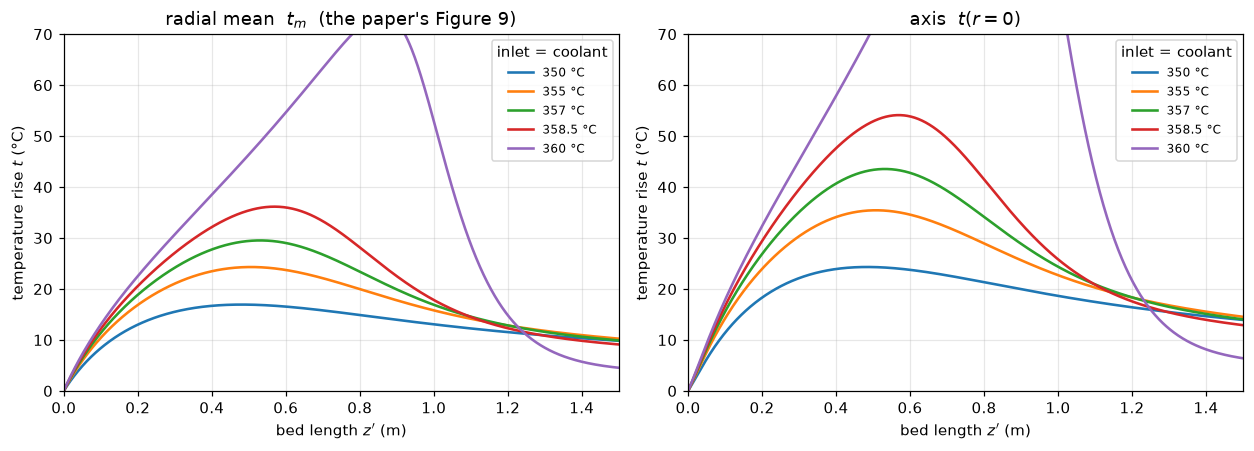

2-D hot spots (radial mean):
  T0 =  350.0 degC : tm_max =  16.94 degC at z' = 0.48 m
  T0 =  355.0 degC : tm_max =  24.31 degC at z' = 0.51 m
  T0 =  357.0 degC : tm_max =  29.53 degC at z' = 0.53 m
  T0 =  358.5 degC : tm_max =  36.16 degC at z' = 0.57 m
  T0 =  360.0 degC : tm_max =  73.84 degC at z' = 0.86 m

paper, p. 25: at 357 degC 'the hot spot, where tm equals about 30 degC' -> computed 29.53 degC (1.6 % from the stated ~30)
at 360 degC the mean rise reaches 74 degC with axis peak 121 degC: far past the knee, though in this rebuild 360.0 degC is still just below the runaway limit located in the next cells


In [6]:
T0_FAMILY = [350.0, 355.0, 357.0, 358.5, 360.0]


def family_2d(case=CASE, **src):
    runs = {T0: tube2d(T0, case=case, **src).march(Z_END, cap=CAP_2D) for T0 in T0_FAMILY}
    return runs, {T0: runs[T0].hot_spot() for T0 in T0_FAMILY}


runs2d, HS2D = family_2d()

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.5, 4.2))
for T0 in T0_FAMILY:
    z, means, axis_vals = runs2d[T0].profiles()
    axL.plot(z * CASE.d_p, means[:, 2], lw=1.7, label=f"{T0:g} °C")
    axR.plot(z * CASE.d_p, axis_vals[:, 2], lw=1.7, label=f"{T0:g} °C")
for ax, ttl in [(axL, "radial mean  $t_m$  (the paper's Figure 9)"),
                (axR, "axis  $t(r{=}0)$")]:
    ax.set(xlabel="bed length $z'$ (m)", ylabel="temperature rise $t$ (°C)",
           title=ttl, xlim=(0, 1.5), ylim=(0, 70))
    ax.legend(fontsize=8, title="inlet = coolant")
plt.tight_layout(); plt.show()

print("2-D hot spots (radial mean):")
for T0 in T0_FAMILY:
    z_hs, tm_hs = HS2D[T0]
    if np.isinf(tm_hs):
        print(f"  T0 = {T0:6.1f} degC : runaway (mean t passed {CAP_2D:.0f} degC inside the bed)")
    else:
        print(f"  T0 = {T0:6.1f} degC : tm_max = {tm_hs:6.2f} degC at z' = {z_hs * CASE.d_p:.2f} m")
TM357 = HS2D[357.0][1]
print(f"\npaper, p. 25: at 357 degC 'the hot spot, where tm equals about 30 degC' -> computed "
      f"{TM357:.2f} degC ({100 * abs(TM357 - 30) / 30:.1f} % from the stated ~30)")
_, _, ax360 = runs2d[360.0].profiles()
print(f"at 360 degC the mean rise reaches {HS2D[360.0][1]:.0f} degC with axis peak "
      f"{ax360[:, 2].max():.0f} degC: far past the knee, though in this rebuild 360.0 degC is "
      "still just below the runaway limit located in the next cells")

### Radial structure, the product maximum, and selectivity

The paper's Figure 8 shows severe radial gradients even in the controlled
case; its Figure 10 shows the selectivity cost of running hotter. Both are
reproduced qualitatively (the figures are not digitised; every quantitative
comparison on this page is against a *stated* number). The consecutive scheme
makes the phthalic anhydride conversion pass through a maximum. The paper says
3 m is enough to reach it at 357 °C; in this rebuild it is not: the bed is
marched on to 10 m below to find where the maximum is.

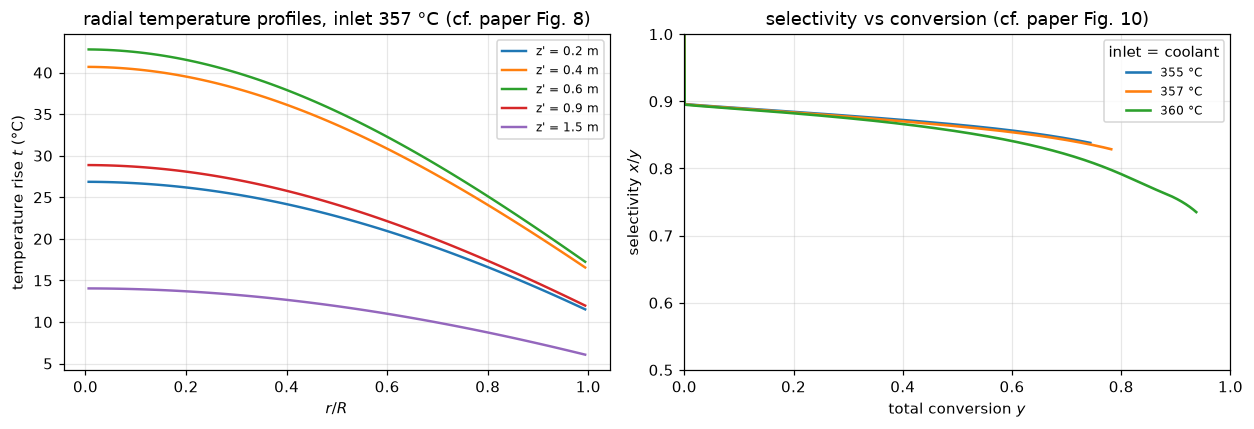

phthalic anhydride conversion at 357 degC: x = 0.573 at 2.0 m, 0.616 at 2.5 m, 0.648 at 3.0 m; the local slope has fallen from 0.37/m in the first meter to 0.06/m at the exit
marched on to 10 m: the maximum is at z' = 6.6 m, x = 0.722; the 3 m exit is 10 % below it
at 360 degC the maximum is at z' = 3.19 m (x = 0.689; 0.689 at 3 m): almost, but still past the 3 m exit
paper, p. 25: 'a length of 3 meters is sufficient to reach the maximum in phthalic anhydride concentration' at 357 degC (row pa_max_length_357 of the stated results, with its p. 24 neighbour) - not reproduced: in this rebuild it almost holds at 360 degC, not at 357
outlet selectivity x/y at 357 degC = 0.829, total conversion y = 0.782 (Figure 10's 357 curve reads ~0.83-0.85 at this conversion; qualitative only)


In [7]:
m357 = runs2d[357.0]
z_marks = [0.2, 0.4, 0.6, 0.9, 1.5]
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11.5, 4.0))
for zm in z_marks:
    axA.plot(m357.r_c / CASE.R, m357.state(zm / CASE.d_p)[:, 2], lw=1.6, label=f"z' = {zm:g} m")
axA.set(xlabel="$r/R$", ylabel="temperature rise $t$ (°C)",
        title="radial temperature profiles, inlet 357 °C (cf. paper Fig. 8)")
axA.legend(fontsize=8)
for T0 in [355.0, 357.0, 360.0]:
    _, means, _ = runs2d[T0].profiles()
    ys = means[:, 0] + means[:, 1]
    sel = np.divide(means[:, 0], ys, out=np.ones_like(ys), where=ys > 1e-6)
    axB.plot(ys, sel, lw=1.7, label=f"{T0:g} °C")
axB.set(xlabel="total conversion $y$", ylabel="selectivity $x/y$",
        title="selectivity vs conversion (cf. paper Fig. 10)", xlim=(0, 1), ylim=(0.5, 1.0))
axB.legend(fontsize=8, title="inlet = coolant")
plt.tight_layout(); plt.show()


def pa_profile(T0C, length_m=3.0, **kw):
    """(z' in m, radial-mean x, w) of the 2-D model on a bed of ``length_m``."""
    m = tube2d(T0C, **kw).march(length_m / CASE.d_p, cap=CAP_2D)
    z, means, _ = m.profiles(n_z=1500 if length_m == 3.0 else 9001)
    return z * CASE.d_p, means[:, 0], means[:, 1]


def pa_maximum(T0C, **kw):
    """Position (m) and value of the phthalic anhydride maximum on a 10 m bed."""
    z, xm, _ = pa_profile(T0C, length_m=10.0, **kw)
    i = int(np.argmax(xm))
    return z[i], xm[i], float(np.interp(3.0, z, xm))


zz, xm, wm = pa_profile(357.0)
x05, x10, x20, x25, x30 = np.interp([0.5, 1.0, 2.0, 2.5, 3.0], zz, xm)
SLOPE_EXIT = 2 * (x30 - x25)
SEL_EXIT, Y_EXIT = xm[-1] / (xm[-1] + wm[-1]), xm[-1] + wm[-1]
Z_PA_357, X_PA_357, X3_357 = pa_maximum(357.0)
Z_PA_360, X_PA_360, X3_360 = pa_maximum(360.0)
PA_SHORT = 1 - X3_357 / X_PA_357
print(f"phthalic anhydride conversion at 357 degC: x = {x20:.3f} at 2.0 m, {x25:.3f} at 2.5 m, "
      f"{x30:.3f} at 3.0 m; the local slope has fallen from {2 * (x10 - x05):.2f}/m in the "
      f"first meter to {SLOPE_EXIT:.2f}/m at the exit")
print(f"marched on to 10 m: the maximum is at z' = {Z_PA_357:.1f} m, x = {X_PA_357:.3f}; "
      f"the 3 m exit is {100 * PA_SHORT:.0f} % below it")
print(f"at 360 degC the maximum is at z' = {Z_PA_360:.2f} m (x = {X_PA_360:.3f}; "
      f"{X3_360:.3f} at 3 m): almost, but still past the 3 m exit")
print("paper, p. 25: 'a length of 3 meters is sufficient to reach the maximum in phthalic "
      "anhydride concentration' at 357 degC (row pa_max_length_357 of the stated results, "
      "with its p. 24 neighbour) - not reproduced: in this rebuild it almost holds at 360 "
      "degC, not at 357")
print(f"outlet selectivity x/y at 357 degC = {SEL_EXIT:.3f}, total conversion y = {Y_EXIT:.3f} "
      "(Figure 10's 357 curve reads ~0.83-0.85 at this conversion; qualitative only)")

### The one-dimensional model with the derived U, and the two runaway limits

The 1-D model must use $U$ built from the same $\lambda_R$ and $\alpha_w$; the
paper prints 82.7 and it is recomputed above. Its Figure 12 family is
reproduced below, then both runaway limits are located **continuously** by
bisection on solves that each start from the inlet, where the paper probed
whole degrees. The runaway criterion is a 150 °C cap on the mean temperature
rise (300 °C in the 1-D model); the validation section shows the located limit
does not depend on that choice.

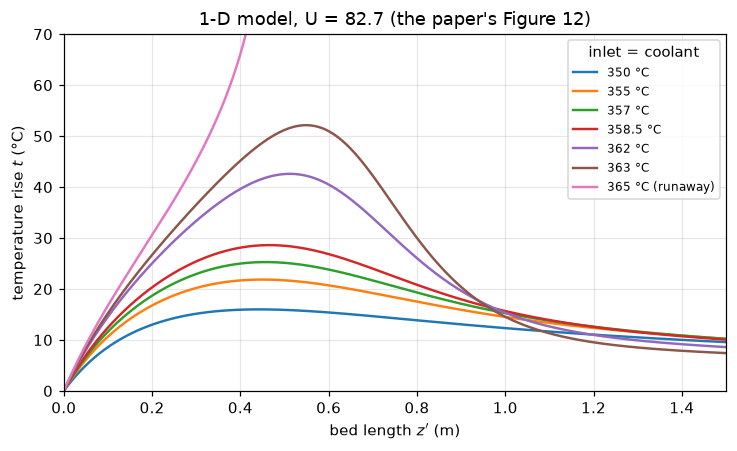

1-D hot spot at 362 degC: 42.6 degC   (paper: 'a rise of only 40 deg')
1-D hot spot at 363 degC: 52.1 degC   (paper: 'a rise of 48 deg')
  deviations: 6.5 % and 8.6 % on quantities that double every ~2 degC at this point


In [8]:
T0_FAMILY_1D = [350.0, 355.0, 357.0, 358.5, 362.0, 363.0, 365.0]


def family_1d(**kw):
    out = {}
    for T0 in T0_FAMILY_1D:
        t1 = march_1d(T0, **kw)
        z = np.linspace(0.0, t1.sol.t[-1], 2500)
        out[T0] = (z, t1.sol.sol(z)[2], t1.ran_away)
    return out


FAM1D = family_1d()
HS1D = {T0: (np.inf if ran else t.max()) for T0, (z, t, ran) in FAM1D.items()}
fig, ax = plt.subplots(figsize=(6.8, 4.2))
for T0, (z, t, ran) in FAM1D.items():
    ax.plot(z * CASE.d_p, t, lw=1.6, label=f"{T0:g} °C" + (" (runaway)" if ran else ""))
ax.set(xlim=(0, 1.5), ylim=(0, 70), xlabel="bed length $z'$ (m)",
       ylabel="temperature rise $t$ (°C)", title="1-D model, U = 82.7 (the paper's Figure 12)")
ax.legend(fontsize=8, title="inlet = coolant"); plt.tight_layout(); plt.show()

RISE362, RISE363 = HS1D[362.0], HS1D[363.0]
print(f"1-D hot spot at 362 degC: {RISE362:.1f} degC   (paper: 'a rise of only 40 deg')")
print(f"1-D hot spot at 363 degC: {RISE363:.1f} degC   (paper: 'a rise of 48 deg')")
print(f"  deviations: {100 * abs(RISE362 - 40) / 40:.1f} % and {100 * abs(RISE363 - 48) / 48:.1f} % "
      "on quantities that double every ~2 degC at this point")

In [9]:
# The two runaway limits, bisected to 1e-4 degC from brackets of 8 degC.
T0C_2D = limit_2d()
T0C_1D = limit_1d()
GAP = T0C_1D - T0C_2D
print(f"2-D runaway limit: T0 = {T0C_2D:.4f} degC   (paper: 'predicts a runaway ... for an "
      "inlet temperature of 360 degC')")
print(f"1-D runaway limit: T0 = {T0C_1D:.4f} degC   ("
      "paper: 'now found to be 365 degC'; Figure 12 probes 363 then 365)")
print(f"gap between the models: {GAP:.2f} degC   ("
      "paper: 'within five degrees ... has to be considered excellent')")

# the paper's statements as labels, each decided directly at the stated temperatures
RA_2D_360 = runs_away_2d(360.0)
IN_BRACKET_1D = (not np.isinf(hot_spot_1d(363.0)[1])) and bool(np.isinf(hot_spot_1d(365.0)[1]))
MARGIN_2D = T0C_2D - 360.0
MARGIN_1D = min(T0C_1D - 363.0, 365.0 - T0C_1D)
print(f"\nDoes the 2-D model run away at 360 degC? {RA_2D_360}: its limit is "
      f"{MARGIN_2D:+.4f} degC from 360. Does the 1-D model hold at 363 and run away at 365? "
      f"{IN_BRACKET_1D} (limit {MARGIN_1D:.2f} degC inside the bracket).")
# how the inputs are read moves the 2-D limit across 360 degC
T0C_2D_PEHR = limit_2d(a=(CASE.a1, 1 / 5.25))               # the printed Pe_hR = 5.25
T0C_2D_NA0P19 = limit_2d(case=replace(CASE, NA0=0.00927))    # p. 19's N_A0
print("So the 1-D limit sits inside the paper's integer bracket (363, 365], and the 2-D limit "
      f"is at the paper's 360 degC within 0.01 degC. Which side of 360 it falls on is set by how "
      "the inputs are read, not by the numerics (the grid and the integrator move it by less "
      f"than 0.001 degC): with the printed Pe_hR = 5.25 instead of the recomputed "
      f"{1 / CASE.a2:.4f} the limit is {T0C_2D_PEHR:.3f} degC, with p. 19's N_A0 = 0.00927 it "
      f"is {T0C_2D_NA0P19:.3f} degC. The 1-D model uses the printed U = 82.7, the 2-D model "
      "the recomputed Pe_hR; that asymmetry alone decides the 2-D label. The continuous gap "
      "is smaller than the quoted five degrees.")

2-D runaway limit: T0 = 360.0060 degC   (paper: 'predicts a runaway ... for an inlet temperature of 360 degC')
1-D runaway limit: T0 = 363.9333 degC   (paper: 'now found to be 365 degC'; Figure 12 probes 363 then 365)
gap between the models: 3.93 degC   (paper: 'within five degrees ... has to be considered excellent')



Does the 2-D model run away at 360 degC? False: its limit is +0.0060 degC from 360. Does the 1-D model hold at 363 and run away at 365? True (limit 0.93 degC inside the bracket).


So the 1-D limit sits inside the paper's integer bracket (363, 365], and the 2-D limit is at the paper's 360 degC within 0.01 degC. Which side of 360 it falls on is set by how the inputs are read, not by the numerics (the grid and the integrator move it by less than 0.001 degC): with the printed Pe_hR = 5.25 instead of the recomputed 5.2433 the limit is 359.964 degC, with p. 19's N_A0 = 0.00927 it is 359.871 degC. The 1-D model uses the printed U = 82.7, the 2-D model the recomputed Pe_hR; that asymmetry alone decides the 2-D label. The continuous gap is smaller than the quoted five degrees.


### The runaway limit against the inlet concentration (Figure 11)

$N_{A0}$ scales with the inlet concentration and cancels out of the mass
equations ($b_1 r_B$ carries no $N_{A0}$), so a lower inlet concentration is
exactly a factor below 1 on the temperature sources. The paper's Figure 11 is
drawn for 44, 38 and 32 g/Nm³; it is not digitised, so only its direction and
shape are compared.

In [10]:
N_R_SWEEP = 48     # the sweeps below use a coarser radial grid; see Validation


def limits_by_conc(concs=(44.0, 38.0, 32.0), **kw):
    return {c: limit_2d(lo=356.0, hi=378.0, tol=1e-3, n_r=N_R_SWEEP,
                        heat_scale=c / 44.0, **kw) for c in concs}


CRIT_BY_CONC = limits_by_conc()
D_44_38 = CRIT_BY_CONC[38.0] - CRIT_BY_CONC[44.0]
D_38_32 = CRIT_BY_CONC[32.0] - CRIT_BY_CONC[38.0]
print("runaway limit vs inlet concentration (n_r = 48, bisected to 1e-3 degC):")
for c, T0c in CRIT_BY_CONC.items():
    print(f"  {c:4.0f} g/Nm3 : T0_crit = {T0c:.2f} degC")
print(f"the limit rises by {D_44_38:.1f} degC from 44 to 38 and a further {D_38_32:.1f} degC "
      "to 32 g/Nm3: the direction and steepening the paper's Figure 11 draws. The figure "
      "itself is not digitised; no quantitative claim is made about its curve positions.")

runaway limit vs inlet concentration (n_r = 48, bisected to 1e-3 degC):
    44 g/Nm3 : T0_crit = 360.00 degC
    38 g/Nm3 : T0_crit = 366.30 degC
    32 g/Nm3 : T0_crit = 374.19 degC
the limit rises by 6.3 degC from 44 to 38 and a further 7.9 degC to 32 g/Nm3: the direction and steepening the paper's Figure 11 draws. The figure itself is not digitised; no quantitative claim is made about its curve positions.


## Validation

Four layers, ordered by what each can and cannot catch. **What no numerical
check below can catch:** a mis-transcription of the *kinetic* constants that
both routes share. $k_1$'s constants have an independent witness (the D2.2
reconciliation above: $27000/1.98 = 13636$ and $\ln A = 19.837$, transcribed
separately from the 1970 paper); $k_2$ and $k_3$ have none (no other document
on disk prints them), so their guard is the reproduction agreement itself,
which is exactly why nothing here was allowed to be fitted.

### 1. The radial operator against the paper's own closed form

With the reaction off, the 2-D model *is* the packed-bed heat exchanger whose
exact Bessel-series solution the paper prints (p. 25). Marching the pymrm
operator from a uniform inlet and comparing the mean-temperature decay against
the series tests the cylindrical `nu=1` divergence, the Robin wall condition,
the symmetry axis and the area-weighted averaging at once, and none of the
kinetics. It **can fail**: the Cartesian operator (`nu=0`) and a flipped
wall-film sign both move it far outside tolerance (break table). The
moment-matching identity behind $U$ is also verified; that one is the paper's
own algebra, labelled an identity, and only checks the transcription of the
$K$ formula.

**A printed defect in that algebra, recorded not repaired:** the paper's
printed $1/K$ series (p. 25) carries $R^2$ where the zero-order moment of its
own $t_m'$ series requires $R^4$, a factor $R^2 = 17.36$ at these dimensions.
The code below uses the correct $R^4$; with the printed $R^2$ the moment
identity misses by exactly that factor, which is how the defect was found.

In [11]:
def hx_error(n_r=80, nu=1, wall_sign=1.0, z_probe=50.0, rtol=1e-11, atol=1e-13, case=CASE):
    """|pymrm - series| / series for the reactionless exchanger at z_probe."""
    m = Tube2D(lambda u: np.zeros_like(u), dispersion=(case.a2,),
               wall=(wall_sign * case.alpha,), R=case.R, n_r=n_r, nu=nu)
    sol = solve_ivp(m.rhs, (0.0, z_probe), np.ones(n_r), method="BDF", jac=m.jac_disp,
                    rtol=rtol, atol=atol, dense_output=True)
    tm_num = float(m.weights @ sol.sol(z_probe))
    tm_ref = exchanger_mean(z_probe, case.a2, case.alpha, case.R)[0]
    return abs(tm_num - tm_ref) / tm_ref


def hx_orders(**kw):
    errs = [hx_error(n_r=n, **kw) for n in (20, 40, 80)]
    return errs, (np.log2(errs[0] / errs[1]), np.log2(errs[1] / errs[2]))


HX_ERRS, HX_ORDERS = hx_orders()
HX_OK = HX_ERRS[2]
HX_NOISE = abs(HX_OK - hx_error(rtol=1e-12, atol=1e-14))
print("exchanger check at z = 50 (z' = 0.15 m), n_r = 80:")
print(f"  pymrm vs printed series : {HX_OK:.2e} relative")
print(f"  grid convergence n_r 20/40/80: {HX_ERRS[0]:.2e} / {HX_ERRS[1]:.2e} / {HX_ERRS[2]:.2e}"
      f"  (observed order {HX_ORDERS[0]:.2f}, {HX_ORDERS[1]:.2f})")
print(f"  finest error over its integrator noise: above 1e3 (here {HX_OK / HX_NOISE:.1e})")


def k_moments(case=CASE, printed=False):
    """K from the closed form and from the zero moment of the t_m' series (p. 25).

    ``printed=True`` uses the paper's printed R^2 in place of the R^4 the moment
    requires.
    """
    a2, alpha, R = case.a2, case.alpha, case.R
    aR = alpha * R
    roots = exchanger_mean(0.0, a2, alpha, R)[1]
    k_closed = (2 * a2 / R) * (4 * alpha / (aR + 4.0))
    pre = 4 * alpha ** 2 * R ** 2 / a2 if printed else 4 * aR ** 2 * R ** 2 / a2
    k_series = 1.0 / (pre * np.sum(1.0 / (roots ** 4 * (roots ** 2 + aR ** 2))))
    return k_closed, k_series


K_CLOSED, K_SERIES = k_moments()
K_ID = abs(K_CLOSED - K_SERIES) / K_CLOSED
K_PRINTED_FACTOR = k_moments(printed=True)[1] / K_CLOSED
print(f"\nK closed form {K_CLOSED:.6f} vs zero-moment series {K_SERIES:.6f}: identity, the "
      f"paper's own algebra, below 1e-8 (here {K_ID:.1e})")
print(f"with the printed R^2 the series misses by a factor {K_PRINTED_FACTOR:.2f} "
      f"(R^2 = {CASE.R ** 2:.2f})")

exchanger check at z = 50 (z' = 0.15 m), n_r = 80:
  pymrm vs printed series : 4.92e-05 relative
  grid convergence n_r 20/40/80: 7.73e-04 / 1.96e-04 / 4.92e-05  (observed order 1.98, 1.99)
  finest error over its integrator noise: above 1e3 (here 2.9e+06)

K closed form 0.033801 vs zero-moment series 0.033801: identity, the paper's own algebra, below 1e-8 (here 6.4e-11)
with the printed R^2 the series misses by a factor 17.36 (R^2 = 17.36)


### 2. Every stated number in the paper, in one table

The complete set of numerical statements the text makes about this case,
against what the rebuilt models give. The three hot-spot rows carry the
paper's own "about"; the runaway rows are integer-degree statements, so their
honest reading is a bracket (the stated limit runs away, the last probed
temperature below it does not).

In [12]:
CASE_LAM075 = replace(CASE, lam_R=0.75)      # changes a2 and alpha together
CASE_AW150 = replace(CASE, alpha_w=150.0)    # changes alpha only
HS_LAM075 = tube2d(360.0, case=CASE_LAM075).march(Z_END, cap=CAP_2D).hot_spot()[1]
HS_AW150 = tube2d(360.0, case=CASE_AW150).march(Z_END, cap=CAP_2D).hot_spot()[1]

rows = [
    ("Pe_hR from G, cp, dp, lam_R", 5.25, CASE.G * CASE.c_p * CASE.d_p / CASE.lam_R, "exact printed"),
    ("U(lam=0.67, aw=134)", 82.7, U_REF, "exact printed"),
    ("U(lam=0.75, aw=134)", 86.0, u_overall(0.75, CASE.alpha_w, CASE.R_tube), "exact printed"),
    ("U(lam=0.67, aw=150)", 88.0, u_overall(CASE.lam_R, 150.0, CASE.R_tube), "exact printed"),
    ("2-D hot spot t_m at 357 degC", 30.0, TM357, "'about'"),
    ("2-D t_m at 360 degC, lam_e=0.75", 35.0, HS_LAM075, "'about'"),
    ("2-D t_m at 360 degC, alpha_w=150", 35.0, HS_AW150, "'about'"),
    ("1-D rise at 362 degC", 40.0, RISE362, "stated"),
    ("1-D rise at 363 degC", 48.0, RISE363, "stated"),
    ("2-D runaway limit", 360.0, T0C_2D, "runs away at (bracket 357-360)"),
    ("1-D runaway limit", 365.0, T0C_1D, "runs away at (bracket 363-365)"),
]
tab = pd.DataFrame(rows, columns=["quantity", "paper", "this page", "qualifier"])
tab["dev %"] = 100 * (tab["this page"] - tab["paper"]).abs() / tab["paper"].abs()
display(tab.assign(**{k: tab[k].map(lambda v: f"{v:.2f}") for k in ("paper", "this page", "dev %")}))

STATED = tab.iloc[4:9]     # the five model-output statements with real content
STATED_MEAN, STATED_WORST = STATED["dev %"].mean(), STATED["dev %"].max()
print(f"five stated model results: mean |dev| = {STATED_MEAN:.1f} %, worst = "
      f"{STATED_WORST:.1f} % (the 363 degC rise, a quantity that doubles every ~2 degC of "
      "inlet temperature at that point)")
print(f"runaway limits: 2-D {T0C_2D:.4f}, {T0C_2D - 360.0:+.4f} degC from the paper's 360, "
      f"a distance set by the input reading (printed Pe_hR: {T0C_2D_PEHR:.4f}); "
      f"1-D {T0C_1D:.4f} in (363, 365]: {363.0 < T0C_1D <= 365.0}")
print("\nREPRODUCTION, not validation: every 'paper' value here is Froment's own 1967 "
      "Crank-Nicolson/numerical-integration result. Nothing was fitted (all model inputs "
      "are printed constants), so the agreement is a genuine test of the transcription and "
      "the solver, but says nothing about the kinetics against reality.")

,quantity,paper,this page,qualifier,dev %
0,"Pe_hR from G, cp, dp, lam_R",5.25,5.24,exact printed,0.13
1,"U(lam=0.67, aw=134)",82.70,82.46,exact printed,0.29
2,"U(lam=0.75, aw=134)",86.00,85.99,exact printed,0.01
3,"U(lam=0.67, aw=150)",88.00,88.25,exact printed,0.29
4,2-D hot spot t_m at 357 degC,30.00,29.53,'about',1.57
5,"2-D t_m at 360 degC, lam_e=0.75",35.00,35.47,'about',1.35
6,"2-D t_m at 360 degC, alpha_w=150",35.00,34.29,'about',2.02
7,1-D rise at 362 degC,40.00,42.59,stated,6.49
8,1-D rise at 363 degC,48.00,52.14,stated,8.63
9,2-D runaway limit,360.00,360.01,runs away at (bracket 357-360),0.00


five stated model results: mean |dev| = 4.0 %, worst = 8.6 % (the 363 degC rise, a quantity that doubles every ~2 degC of inlet temperature at that point)
runaway limits: 2-D 360.0060, +0.0060 degC from the paper's 360, a distance set by the input reading (printed Pe_hR: 359.9642); 1-D 363.9333 in (363, 365]: True

REPRODUCTION, not validation: every 'paper' value here is Froment's own 1967 Crank-Nicolson/numerical-integration result. Nothing was fitted (all model inputs are printed constants), so the agreement is a genuine test of the transcription and the solver, but says nothing about the kinetics against reality.


### 3. A second, independent route to the headline numbers

The headline quantities are recomputed by routes that share **no assembly
code** with the pymrm models:

- **2-D**: an independently written conservative finite-difference operator
  (hand-built face-flux balances, one-sided Robin ghost at the wall) marched
  with a *different* stiff integrator (`Radau` vs `BDF`);
- **1-D**: the pymrm steady boundary-value route (`construct_convflux_upwind`
  and `newton`, the D2.2 machinery) against the adaptive march used above.

The routes share the printed constants and nothing else: the Newton solve of
the 1-D route starts from zero in every field, not from the march, and raises
if it does not converge. Agreement therefore tests discretisation, integration
and assembly: everything except the transcription, which is guarded separately
above. A third comparison checks the Jacobian: the 2-D march with the
integrator's own finite-difference Jacobian.

In [13]:
def indep_2d(T0C, n_r=80, case=CASE, cap=CAP_2D):
    """Independent route: hand-built FD + Radau. No pymrm calls anywhere."""
    a1i, a2i, al, Rdim = case.a1, case.a2, case.alpha, case.R
    lnA, E, Rg, kelvin = np.array(case.lnA), np.array(case.E), case.R_gas, case.kelvin
    b1, b2, b3, NA0, N0 = case.b1, case.b2, case.b3, case.NA0, case.N0
    r_f = np.linspace(0.0, Rdim, n_r + 1)
    r_c = 0.5 * (r_f[:-1] + r_f[1:])
    h = r_f[1] - r_f[0]

    def lap(D, robin):
        A = np.zeros((n_r, n_r))
        for i in range(n_r):
            if i > 0:
                A[i, i - 1] += D * r_f[i] / (h * h * r_c[i])
                A[i, i] -= D * r_f[i] / (h * h * r_c[i])
            if i < n_r - 1:
                A[i, i + 1] += D * r_f[i + 1] / (h * h * r_c[i])
                A[i, i] -= D * r_f[i + 1] / (h * h * r_c[i])
            elif robin:   # wall flux -D dt/dr = D*al*t_wall, ghost-free one-sided
                A[i, i] -= D * r_f[i + 1] * al / ((1 + al * h / 2) * h * r_c[i])
        return A

    Lm, Lt = lap(a1i, False), lap(a2i, True)
    wgt = (r_f[1:] ** 2 - r_f[:-1] ** 2) / Rdim ** 2

    def rhs(z, u):
        x, w, t = u[:n_r], u[n_r:2 * n_r], u[2 * n_r:]
        T = t + T0C + kelvin
        k1 = np.exp(lnA[0] - E[0] / (Rg * T))
        k2 = np.exp(lnA[1] - E[1] / (Rg * T))
        k3 = np.exp(lnA[2] - E[2] / (Rg * T))
        y = x + w
        rB = NA0 * N0 * (k1 * (1 - y) - k2 * x)
        rC = NA0 * N0 * (k2 * x + k3 * (1 - y))
        return np.concatenate([Lm @ x + b1 * rB, Lm @ w + b1 * rC,
                               Lt @ t + b2 * rB + b3 * rC])

    def hit_cap(z, u):
        return wgt @ u[2 * n_r:] - cap
    hit_cap.terminal, hit_cap.direction = True, 1
    sol = solve_ivp(rhs, (0.0, case.z_end), np.zeros(3 * n_r), method="Radau",
                    rtol=1e-8, atol=1e-10, dense_output=True, events=hit_cap)
    if sol.t_events[0].size:
        return np.inf
    zz = np.linspace(0.0, sol.t[-1], 4000)
    return float((sol.sol(zz)[2 * n_r:, :].T @ wgt).max())


def indep_limit(lo=359.95, hi=360.05, tol=1e-4, n_r=80):
    """Bisect the independent route; critical_inlet checks both bracket ends first."""
    return critical_inlet(lambda T0: bool(np.isinf(indep_2d(T0, n_r=n_r))), lo, hi, tol)[0]


TM357_INDEP = indep_2d(357.0, n_r=40)
ROUTE2_TM = abs(TM357_INDEP - TM357) / TM357
print("2-D hot spot at 357 degC, two independent routes:")
print(f"  pymrm operators + BDF, n_r = 80      : {TM357:.4f} degC")
print(f"  hand-built FD + Radau, n_r = 40      : {TM357_INDEP:.4f} degC   (rel diff {ROUTE2_TM:.2e})")
print("  (deliberately different grids, so the reported difference is the deterministic "
      "discretisation gap, not integrator noise)")
T0C_2D_INDEP = indep_limit()
ROUTE2_CRIT = abs(T0C_2D_INDEP - T0C_2D)
print(f"2-D runaway limit, independent route on n_r = 80: {T0C_2D_INDEP:.4f} degC (pymrm "
      f"route {T0C_2D:.4f}), both bisected to 1e-4 degC; they agree to better than 1e-3 degC "
      f"(here {ROUTE2_CRIT:.1e})")

print("\n1-D hot spots, adaptive march vs pymrm steady BVP (n_z = 4000, cold-started Newton):")
ROUTE2_1D = {}
for T0 in (357.0, 362.0, 363.0):
    b = bvp_1d(T0)
    bvp = b.hot_spot()[1]
    marched = HS1D[T0] if T0 in HS1D else hot_spot_1d(T0)[1]
    ROUTE2_1D[T0] = abs(bvp - marched) / marched
    print(f"  T0 = {T0:5.1f}: march {marched:7.3f}  pymrm BVP {bvp:7.3f}  rel diff "
          f"{ROUTE2_1D[T0]:.2e}  ({b.result.nit} Newton iterations)")


def bvp_order(T0=363.0, n=(2000, 4000, 8000), reference=None):
    ref = HS1D[T0] if reference is None else reference
    errs = [abs(bvp_1d(T0, n_z=k).hot_spot()[1] - ref) / ref for k in n]
    return errs, np.log2(errs[0] / errs[1]), np.log2(errs[1] / errs[2])


BVP_ERRS, *BVP_ORD = bvp_order()
print(f"  363 degC on n_z = 2000/4000/8000: {BVP_ERRS[0]:.2e} / {BVP_ERRS[1]:.2e} / "
      f"{BVP_ERRS[2]:.2e}, observed order {BVP_ORD[0]:.2f}, {BVP_ORD[1]:.2f}: the first-order "
      "upwind bias, shrinking with n_z")


def march_fd_jacobian(T0C, rtol=1e-8):
    """The 2-D march with no Jacobian given to the integrator (finite differences)."""
    m = tube2d(T0C)
    m.sol = solve_ivp(m.rhs, (0.0, Z_END), np.zeros(m.shape).ravel(), method="BDF",
                      rtol=rtol, atol=rtol * 1e-2, dense_output=True)
    m.ran_away = False
    return m.hot_spot()[1]


_t = time.perf_counter(); TM357_FDJ = march_fd_jacobian(357.0); _t_fd = time.perf_counter() - _t
_t = time.perf_counter(); tube2d(357.0).march(Z_END, cap=CAP_2D); _t_ex = time.perf_counter() - _t
FDJ_GAP = abs(TM357_FDJ - TM357)
print(f"\n2-D march at 357 degC with the integrator's finite-difference Jacobian "
      f"against the exact one: gap below 1e-5 degC (here {FDJ_GAP:.1e}); "
      f"runtime (here {_t_fd:.2f} s against {_t_ex:.2f} s)")

2-D hot spot at 357 degC, two independent routes:
  pymrm operators + BDF, n_r = 80      : 29.5277 degC
  hand-built FD + Radau, n_r = 40      : 29.5419 degC   (rel diff 4.83e-04)
  (deliberately different grids, so the reported difference is the deterministic discretisation gap, not integrator noise)


2-D runaway limit, independent route on n_r = 80: 360.0057 degC (pymrm route 360.0060), both bisected to 1e-4 degC; they agree to better than 1e-3 degC (here 2.4e-04)

1-D hot spots, adaptive march vs pymrm steady BVP (n_z = 4000, cold-started Newton):
  T0 = 357.0: march  25.281  pymrm BVP  25.251  rel diff 1.17e-03  (5 Newton iterations)
  T0 = 362.0: march  42.595  pymrm BVP  42.478  rel diff 2.75e-03  (7 Newton iterations)


  T0 = 363.0: march  52.142  pymrm BVP  51.915  rel diff 4.35e-03  (7 Newton iterations)


  363 degC on n_z = 2000/4000/8000: 8.64e-03 / 4.35e-03 / 2.18e-03, observed order 0.99, 0.99: the first-order upwind bias, shrinking with n_z



2-D march at 357 degC with the integrator's finite-difference Jacobian against the exact one: gap below 1e-5 degC (here 2.8e-09); runtime (here 0.21 s against 0.13 s)


### 4. Refinement and threshold insensitivity

Grid and tolerance refinement for the headline hot spot, then the runaway
limit's insensitivity to the arbitrary 150 °C cap, and the limit on a finer
radial grid: is "360 °C is still controlled" a property of the model or of
the grid?

In [14]:
def grid_study(n_list=(20, 40, 80, 160), weights=None):
    """Hot spot at 357 degC on several radial grids; ``weights(m)`` replaces the mean's."""
    out = {}
    for nn in n_list:
        m = tube2d(357.0, n_r=nn)
        if weights is not None:
            m.weights = weights(m)
        out[nn] = m.march(Z_END, cap=CAP_2D).hot_spot()[1]
    order = np.log2(abs(out[20] - out[80]) / abs(out[40] - out[160]))
    return out, order, abs(out[80] - out[160])


TM_BY_N, GRID_ORDER, E80 = grid_study()
print("grid refinement, 2-D hot spot at 357 degC (BDF rtol 1e-8):")
for nn, v in TM_BY_N.items():
    print(f"  n_r = {nn:4d}: tm_max = {v:.4f} degC")
print(f"  apparent order {GRID_ORDER:.1f}; n_r = 80 sits {E80:.4f} degC from n_r = 160")


def rtol_study(rtols=(1e-6, 1e-8, 1e-10)):
    return {rt: tube2d(357.0).march(Z_END, cap=CAP_2D, rtol=rt).hot_spot()[1] for rt in rtols}


TM_BY_RTOL = rtol_study()
RTOL_SPREAD = max(TM_BY_RTOL.values()) - min(TM_BY_RTOL.values())
print("\nintegrator tolerance, same quantity, n_r = 80:")
for rt, v in TM_BY_RTOL.items():
    print(f"  rtol = {rt:.0e}: tm_max = {v:.4f} degC")
print(f"  spread below 1e-3 degC (here {RTOL_SPREAD:.1e})")


def cap_study(caps=(100.0, 150.0, 250.0)):
    return {cap: limit_2d(tol=1e-3, cap=cap, n_r=N_R_SWEEP) for cap in caps}


CRIT_BY_CAP = cap_study()
CAP_RANGE = max(CRIT_BY_CAP.values()) - min(CRIT_BY_CAP.values())
print("\nrunaway-cap insensitivity (2-D limit, n_r = 48, bisected to 1e-3 degC):")
for cap, v in CRIT_BY_CAP.items():
    print(f"  cap = {cap:5.0f} degC: T0_crit = {v:.4f} degC")
print(f"  range across a 2.5x range of the cap below 2e-3 degC (here {CAP_RANGE:.1e}): near "
      "criticality the peak passes any finite cap almost at once.")



def knee_peak(T0C):
    """Peak radial-mean rise of the 2-D model, marched with a 2000 degC cap."""
    m = tube2d(T0C).march(Z_END, cap=2000.0)
    return 2000.0 if m.ran_away else m.hot_spot()[1]


KNEE = (knee_peak(T0C_2D - 5e-4), knee_peak(T0C_2D + 5e-4))
print(f"\nthe knee, n_r = 80: peak mean rise {KNEE[0]:.0f} degC at 5e-4 degC below the limit and "
      f"{KNEE[1]:.0f} degC at 5e-4 degC above it; any cap between the two gives the same limit "
      f"to 1e-3 degC, and the {CAP_2D:.0f} degC cap sits between them.")

RA_360_N160 = runs_away_2d(360.0, n_r=160)
T0C_2D_N160 = limit_2d(lo=360.0, hi=360.1, tol=1e-4, n_r=160)
print(f"\nn_r = 160: runs away at 360 degC? {RA_360_N160}; limit {T0C_2D_N160:.4f} degC, "
      f"within 1e-3 degC of n_r = 80 (n_r = 48 gives {CRIT_BY_CAP[150.0]:.4f}). The limit "
      "rises with the grid by less than 0.001 degC per doubling, so the grid does not decide "
      "the label; the input reading does (above).")

grid refinement, 2-D hot spot at 357 degC (BDF rtol 1e-8):
  n_r =   20: tm_max = 29.5713 degC
  n_r =   40: tm_max = 29.5365 degC
  n_r =   80: tm_max = 29.5277 degC
  n_r =  160: tm_max = 29.5255 degC
  apparent order 2.0; n_r = 80 sits 0.0022 degC from n_r = 160



integrator tolerance, same quantity, n_r = 80:
  rtol = 1e-06: tm_max = 29.5277 degC
  rtol = 1e-08: tm_max = 29.5277 degC
  rtol = 1e-10: tm_max = 29.5277 degC
  spread below 1e-3 degC (here 2.1e-05)



runaway-cap insensitivity (2-D limit, n_r = 48, bisected to 1e-3 degC):
  cap =   100 degC: T0_crit = 360.0044 degC
  cap =   150 degC: T0_crit = 360.0044 degC
  cap =   250 degC: T0_crit = 360.0044 degC
  range across a 2.5x range of the cap below 2e-3 degC (here 0.0e+00): near criticality the peak passes any finite cap almost at once.



the knee, n_r = 80: peak mean rise 85 degC at 5e-4 degC below the limit and 869 degC at 5e-4 degC above it; any cap between the two gives the same limit to 1e-3 degC, and the 150 degC cap sits between them.



n_r = 160: runs away at 360 degC? False; limit 360.0066 degC, within 1e-3 degC of n_r = 80 (n_r = 48 gives 360.0044). The limit rises with the grid by less than 0.001 degC per doubling, so the grid does not decide the label; the input reading does (above).


**Four results, stated to the precision the computations support.**

- The 2-D limit is 360.006 °C, at the paper's 360 within 0.01 °C. Which side
  of 360 it falls on is set by how the inputs are read (the printed
  $\mathrm{Pe}_{hR} = 5.25$ puts it below 360), not by the numerics.
- Bisected to 1e-4 °C, the margin above 360 °C is 0.006 °C.
- At $\mathrm{Pe}_{mR} = 8$, on the same radial grid and bisected to 1e-4 °C,
  the runaway limit shifts by 0.043 °C (What pymrm adds): resolved, and still
  small, about a seventh of the shift from a 1 % change in the heat-transfer
  parameters.
- At 357 °C the phthalic anhydride maximum is at 6.6 m and the 3 m exit is
  10 % below it, so the paper's "a length of 3 meters is sufficient to reach
  the maximum" is not reproduced at 357 °C. It almost holds at 360 °C, where
  the maximum is at 3.2 m, still past the 3 m exit.

### Claims: what each number is, and how it is checked

Every number the page stands behind is registered once, in the cell below
(`docs/claims-design.md` in the gallery repository):

- a **value** is a result whose size is set by physics, the data or the
  discretisation. CI holds it to a relative tolerance of the committed
  baseline, 5 % unless the cell says otherwise. The runaway limits carry
  1e-5 (0.004 °C): they are bisected to 1e-4 °C and identical under three
  BLAS kernels, so the tolerance is set by the bisection, not by a
  sensitivity (a 0.15 K Kelvin offset shifts every limit by exactly 0.15 °C,
  because the model depends on the inlet temperature only through
  $T_0 + 273.15$);
- a **bound** is a quantity whose size is not physics: an identity, a
  solver-tolerance gap, a convergence order. It is checked against its stated
  limits on every run and states its basis;
- an **exact** result is a label, with its distance to the threshold that
  decided it.

In [15]:
# --- transcription identities and derived constants ---------------------------
for k, v in DEV.items():
    claims.value(k, v)
claims.value("na0_from_44gnm3_rel", NA0_DEV)
claims.value("re_from_G", RE)
claims.value("m_feed_from_composition", M_FEED, rtol=1e-3)
claims.value("m_feed_rel_pct", 100 * (M_FEED / CASE.M_m - 1))
claims.value("adiabatic_rise_AB_C", ADIABATIC_AB)
claims.value("dh3_literal_ratio", DH3_LITERAL_RATIO)
claims.value("kelvin_offset_rel_T_pct", 100 * 0.15 / (357 + 273.15))
claims.value("k1_shift_kelvin_pct", 100 * (np.exp(CASE.E[0] / CASE.R_gas * 0.15 / 630.0 ** 2) - 1))
claims.bound("d22_shared_max_rel", D22_SHARED_MAX, max=1e-3, basis="chosen",
             note="two transcriptions of the same printed constants; E1/R_gas carries the "
                  "rounding of 13636")
claims.value("d22_gcp_rel", D22_GCP)
# --- the radial operator against the printed series ------------------------------
claims.value("hx_series_rel_z50", HX_OK)
claims.bound("hx_order_20_40", HX_ORDERS[0], min=1.9, max=2.1, basis="theory")
claims.bound("hx_order_40_80", HX_ORDERS[1], min=1.9, max=2.1, basis="theory")
claims.bound("hx_finest_over_noise", HX_OK / HX_NOISE, min=1e3, basis="theory",
             note="noise: change of the error when the integrator tolerances drop tenfold")
claims.bound("k_moment_identity_rel", K_ID, max=1e-8, basis="identity",
             note="the paper's own algebra; the series is truncated at roots below 150")
claims.value("k_printed_series_factor", K_PRINTED_FACTOR, rtol=1e-3)
# --- the stated results --------------------------------------------------------------
claims.value("tm2d_hotspot_357_C", TM357)
claims.value("tm2d_357_vs_paper_rel", abs(TM357 - 30.0) / 30.0)
claims.value("z_hotspot_357_m", HS2D[357.0][0] * CASE.d_p)
for T0 in (350.0, 355.0, 358.5, 360.0):
    claims.value(f"tm2d_{T0:g}_C".replace(".", ""), HS2D[T0][1])
claims.value("rise1d_362_C", RISE362)
claims.value("rise1d_362_vs_paper_rel", abs(RISE362 - 40.0) / 40.0)
claims.value("rise1d_363_C", RISE363)
claims.value("rise1d_363_vs_paper_rel", abs(RISE363 - 48.0) / 48.0)
claims.value("tm2d_360_lam075_C", HS_LAM075)
claims.value("tm2d_360_lam075_vs_paper_rel", abs(HS_LAM075 - 35.0) / 35.0)
claims.value("tm2d_360_aw150_C", HS_AW150)
claims.value("tm2d_360_aw150_vs_paper_rel", abs(HS_AW150 - 35.0) / 35.0)
claims.value("stated_mean_dev_pct", STATED_MEAN)
claims.value("stated_worst_dev_pct", STATED_WORST)
# --- the runaway limits ----------------------------------------------------------------
claims.value("t0crit_2d_C", T0C_2D, rtol=1e-5)
claims.value("t0crit_1d_C", T0C_1D, rtol=1e-5)
claims.value("t0crit_2d_minus_360_C", MARGIN_2D)
claims.value("runaway_gap_C", GAP, rtol=1e-3)
claims.value("t0crit_2d_printed_pehr_C", T0C_2D_PEHR, rtol=1e-5)
claims.value("t0crit_2d_na0_p19_C", T0C_2D_NA0P19, rtol=1e-5)
claims.bound("knee_peak_below_C", KNEE[0], max=CAP_2D, basis="chosen",
             note="peak radial-mean rise 5e-4 degC below the limit, marched with no cap")
claims.bound("knee_peak_above_C", KNEE[1], min=CAP_2D, basis="chosen",
             note="peak radial-mean rise 5e-4 degC above the limit, or its last value at a 2000 degC cap")
claims.exact("runs_away_2d_at_360", RA_2D_360, margin=MARGIN_2D, min_margin=1e-3,
             note="margin: distance of the bisected limit above 360 degC. min_margin covers "
                  "the numerics only (grid, integrator); a different reading of the inputs "
                  "moves the limit across 360 (t0crit_2d_printed_pehr_C)")
claims.exact("runs_away_2d_at_360_n160", RA_360_N160, margin=T0C_2D_N160 - 360.0,
             min_margin=1e-3)
claims.exact("in_bracket_1d", IN_BRACKET_1D, margin=MARGIN_1D, min_margin=0.1,
             note="holds at 363 and runs away at 365; margin: distance of the limit to the "
                  "nearer end")
claims.value("t0crit_38_minus_44_C", D_44_38, rtol=1e-3)
claims.value("t0crit_32_minus_38_C", D_38_32, rtol=1e-3)
claims.value("limit_steepening_ratio", D_38_32 / D_44_38, rtol=0.02)
# --- the product maximum and selectivity -----------------------------------------------
claims.value("x357_exit_slope_per_m", SLOPE_EXIT)
claims.value("x357_at_3m", X3_357)
claims.value("x357_max", X_PA_357)
claims.value("z_pa_max_357_m", Z_PA_357)
claims.value("pa_shortfall_at_3m_357", PA_SHORT)
claims.value("z_pa_max_360_m", Z_PA_360)
claims.exact("pa_max_within_3m_357", bool(Z_PA_357 <= 3.0), margin=(Z_PA_357 - 3.0) / 3.0,
             min_margin=0.1)
claims.value("selectivity_exit_357", SEL_EXIT)
claims.value("conversion_exit_357", Y_EXIT)
# --- second routes ------------------------------------------------------------------------
claims.value("route2_tm357_rel", ROUTE2_TM)
claims.bound("route2_t0crit_2d_absdiff", ROUTE2_CRIT, max=1e-3, basis="chosen",
             note="two discretisations at n_r = 80, both bisected to 1e-4 degC")
claims.value("route2_rise1d_363_rel", ROUTE2_1D[363.0])
claims.bound("bvp_upwind_order", BVP_ORD[1], min=0.9, max=1.1, basis="theory",
             note="first-order upwind, n_z 4000 to 8000")
claims.bound("fd_jacobian_vs_exact_tm357", FDJ_GAP, max=1e-5, basis="tolerance",
             note="BDF rtol 1e-8 in both routes")
# --- refinement and the cap ----------------------------------------------------------------
claims.bound("tm357_grid_order", GRID_ORDER, min=1.8, max=2.2, basis="theory")
claims.value("tm357_n80_vs_n160_C", E80)
claims.bound("tm357_rtol_spread_C", RTOL_SPREAD, max=1e-3, basis="tolerance",
             note="BDF rtol 1e-6 to 1e-10")
claims.bound("t0crit_2d_n80_vs_n160_C", abs(T0C_2D_N160 - T0C_2D), max=1e-3, basis="chosen",
             note="grid effect on the 2-D limit; the label 'runs away at 360' depends on "
                  "inputs, not on this")
claims.bound("t0crit_cap_range_C", CAP_RANGE, max=2e-3, basis="chosen",
             note="twice the bisection tolerance of 1e-3 degC")

### The defect-injection table

Each row breaks one thing on purpose,
**re-runs** the computation behind one claim with the defect in place, and
hands the result to `claims.breaks`, which records whether the claim's own
check (its tolerance or its bound) catches it. Several rows are the
transcription traps this page actually faced: the two thousands separators
taken literally, the unprinted Kelvin offset, the unit of "44". Every claim
must be failed by at least one row, and the last cell of the page raises
otherwise.

In [16]:
BREAK = []


def brk(name, metric, value, note=""):
    """One injected defect: ``value`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(name, metric, value)
    BREAK.append(dict(defect=name, metric=metric, clean=claims[metric], broken=value,
                      caught=caught, note=note))


# --- transcription ----------------------------------------------------------------
CASE_G_LIT = replace(CASE, G=4.684)
CASE_DH3_LIT = replace(CASE, dH3=1090.0)
CASE_K273 = replace(CASE, kelvin=273.0)
CASE_RT_DIAM = replace(CASE, d_t=2 * CASE.d_t)          # R' taken as the diameter
brk("G read literally as 4.684", "pehr_identity_rel", identity_devs(CASE_G_LIT)["pehr_identity_rel"])
brk("G read literally as 4.684", "re_from_G", reynolds(CASE_G_LIT))
for k in ("u_ref_identity_rel", "u_lam075_identity_rel", "u_aw150_identity_rel"):
    brk("tube radius R' taken as the diameter", k, identity_devs(CASE_RT_DIAM)[k])
brk("44 read as mol/m3, not g/Nm3", "na0_from_44gnm3_rel",
    abs(na0_from_conc(44.0 * 106.17) - CASE.NA0) / CASE.NA0)
brk("air molar mass taken as N2's (28.01)", "m_feed_from_composition", m_feed(CASE, 28.01))
brk("air molar mass taken as N2's (28.01)", "m_feed_rel_pct",
    100 * (m_feed(CASE, 28.01) / CASE.M_m - 1))
_case_cvol = replace(CASE, c_p=0.323)
brk("D2.2's volumetric c_p 0.323 taken as mass basis", "adiabatic_rise_AB_C",
    _case_cvol.NA0 / _case_cvol.M_m * 1000.0 * _case_cvol.dH1 / 1000.0 / _case_cvol.c_p)
brk("-dH1 compared in kcal/kmol with dH3 in kcal/gmol", "dh3_literal_ratio",
    CASE.dH1 / 1.090)
brk("offset taken relative to 357 degC, not 630 K", "kelvin_offset_rel_T_pct", 100 * 0.15 / 357)
brk("k1 shift with E2 instead of E1", "k1_shift_kelvin_pct",
    100 * (np.exp(CASE.E[1] / CASE.R_gas * 0.15 / 630.0 ** 2) - 1))
_rec_bad = reconcile(replace(CASE, rho_b=1030.0), D22)
brk("rho_b transposed to 1030", "d22_shared_max_rel", float(_rec_bad["rel diff"][:8].max()))
brk("G*cp against D2.2's u without its c_p", "d22_gcp_rel",
    abs(CASE.G * CASE.c_p - D22["u"]) / D22["u"])

# --- the radial operator --------------------------------------------------------------------
_hx_nu0 = hx_orders(nu=0)
brk("nu = 0 (Cartesian radial operator)", "hx_series_rel_z50", _hx_nu0[0][2],
    "wrong geometry: a slab has more cross-section near the wall")
brk("wall film sign flipped (b = -alpha)", "hx_series_rel_z50", hx_error(wall_sign=-1.0),
    "the outward-normal trap: the film heats instead of cools")
brk("nu = 0 (Cartesian radial operator)", "hx_order_20_40", _hx_nu0[1][0])
brk("nu = 0 (Cartesian radial operator)", "hx_order_40_80", _hx_nu0[1][1])
brk("integrator tolerances 1e-6 / 1e-8", "hx_finest_over_noise",
    HX_OK / abs(hx_error(rtol=1e-6, atol=1e-8) - hx_error(rtol=1e-12, atol=1e-14)))
_kc, _ks = k_moments(printed=True)
brk("the printed R^2 in the 1/K series", "k_moment_identity_rel", abs(_kc - _ks) / _kc)
_case_rd = replace(CASE, d_t=2 * CASE.d_t)
brk("R taken from the diameter", "k_printed_series_factor",
    k_moments(_case_rd, printed=True)[1] / k_moments(_case_rd)[0])

# --- the stated results ---------------------------------------------------------------------
_runs_swap = {T0: tube2d(T0, k_order=(0, 2, 1)).march(Z_END, cap=CAP_2D) for T0 in (357.0,)}
_tm_swap = _runs_swap[357.0].hot_spot()[1]
brk("k2 <-> k3 swapped", "tm2d_hotspot_357_C", _tm_swap,
    "no independent witness prints k2, k3, so the reproduction is their only guard")
brk("k2 <-> k3 swapped", "tm2d_357_vs_paper_rel", abs(_tm_swap - 30.0) / 30.0)
brk("heat Pe taken = mass Pe (a2 = 1/10)", "tm2d_hotspot_357_C",
    tube2d(357.0, a=(CASE.a1, 0.1)).march(Z_END, cap=CAP_2D).hot_spot()[1],
    "the two Peclet numbers differ by 1.9x")
brk("dH3 read literally as -1.090 kcal/gmol", "tm2d_hotspot_357_C",
    tube2d(357.0, case=CASE_DH3_LIT).march(Z_END, cap=CAP_2D).hot_spot()[1], "combustion heat 1000x low")
_hs_g_lit = tube2d(357.0, case=CASE_G_LIT).march(Z_END, cap=CAP_2D).hot_spot()
brk("G read literally as 4.684", "tm2d_hotspot_357_C", _hs_g_lit[1],
    "every G-bearing group 1000x off: the 3 m bed behaves like 3 km of packing")
brk("G read literally as 4.684", "z_hotspot_357_m", _hs_g_lit[0] * CASE.d_p,
    "the hot spot moves to within a millimetre of the inlet")
_runs_k273, _hs_k273 = family_2d(CASE_K273)
_runs_kswap, _hs_kswap = family_2d(k_order=(0, 2, 1))
brk("Kelvin offset 273 instead of 273.15", "z_hotspot_357_m", _hs_k273[357.0][0] * CASE.d_p,
    "0.15 K moves the hot spot by less than its 5 % tolerance")
brk("k2 <-> k3 swapped", "z_hotspot_357_m", _hs_kswap[357.0][0] * CASE.d_p,
    "the swap changes the height of the hot spot more than its position")
for T0 in (350.0, 355.0, 358.5, 360.0):
    brk("Kelvin offset 273 instead of 273.15", f"tm2d_{T0:g}_C".replace(".", ""), _hs_k273[T0][1],
        "0.15 K moves the cooler hot spots by 1 to 3 %, inside the 5 % tolerance; "
        "the k2 <-> k3 row fails them")
    brk("k2 <-> k3 swapped", f"tm2d_{T0:g}_C".replace(".", ""), _hs_kswap[T0][1])
_fam_swap = family_1d(k_order=(0, 2, 1))
_hs1_swap = {T0: (np.inf if ran else t.max()) for T0, (z, t, ran) in _fam_swap.items()}
for T0, paper in ((362.0, 40.0), (363.0, 48.0)):
    brk("k2 <-> k3 swapped (1-D)", f"rise1d_{T0:g}_C", _hs1_swap[T0])
    brk("k2 <-> k3 swapped (1-D)", f"rise1d_{T0:g}_vs_paper_rel", abs(_hs1_swap[T0] - paper) / paper)
_hs_lam_a2 = tube2d(360.0, a=(CASE.a1, CASE_LAM075.a2)).march(Z_END, cap=CAP_2D).hot_spot()[1]
brk("lam_e = 0.75 put in a2 only (alpha kept)", "tm2d_360_lam075_C", _hs_lam_a2,
    "lambda_R enters the wall group too")
brk("lam_e = 0.75 put in a2 only (alpha kept)", "tm2d_360_lam075_vs_paper_rel",
    abs(_hs_lam_a2 - 35.0) / 35.0)
_hs_aw_swap = tube2d(360.0, case=CASE_AW150, k_order=(0, 2, 1)).march(Z_END, cap=CAP_2D).hot_spot()[1]
brk("k2 <-> k3 swapped", "tm2d_360_aw150_C", _hs_aw_swap)
brk("k2 <-> k3 swapped", "tm2d_360_aw150_vs_paper_rel", abs(_hs_aw_swap - 35.0) / 35.0)
_stated_swap = np.array([abs(_tm_swap - 30) / 30, abs(HS_LAM075 - 35) / 35, abs(HS_AW150 - 35) / 35,
                         abs(_hs1_swap[362.0] - 40) / 40, abs(_hs1_swap[363.0] - 48) / 48]) * 100
brk("k2 <-> k3 swapped (both models)", "stated_mean_dev_pct", _stated_swap.mean())
brk("k2 <-> k3 swapped (both models)", "stated_worst_dev_pct", _stated_swap.max())

# --- the runaway limits ------------------------------------------------------------------
T0C_2D_K273 = limit_2d(case=CASE_K273)
T0C_1D_K273 = limit_1d(case=CASE_K273)
brk("Kelvin offset 273 instead of 273.15", "t0crit_2d_C", T0C_2D_K273)
brk("Kelvin offset 273 instead of 273.15", "t0crit_1d_C", T0C_1D_K273)
brk("Kelvin offset 273 instead of 273.15", "t0crit_2d_minus_360_C", T0C_2D_K273 - 360.0)
brk("Kelvin offset 273 instead of 273.15", "t0crit_2d_printed_pehr_C",
    limit_2d(a=(CASE.a1, 1 / 5.25), case=CASE_K273))
brk("Kelvin offset 273 instead of 273.15", "t0crit_2d_na0_p19_C",
    limit_2d(case=replace(CASE_K273, NA0=0.00927)))
brk("n_r = 48 (bisected to 1e-3) against n_r = 160", "t0crit_2d_n80_vs_n160_C",
    abs(T0C_2D_N160 - CRIT_BY_CAP[150.0]))
brk("knee probed 0.05 degC above the limit", "knee_peak_below_C", knee_peak(T0C_2D + 0.05))
brk("knee probed 0.05 degC below the limit", "knee_peak_above_C", knee_peak(T0C_2D - 0.05))
brk("Kelvin offset 273 in the 1-D model only", "runaway_gap_C", T0C_1D_K273 - T0C_2D)
_case_aw99 = replace(CASE, alpha_w=0.99 * CASE.alpha_w)
brk("alpha_w 1 % low", "runs_away_2d_at_360", runs_away_2d(360.0, case=_case_aw99))
brk("alpha_w 1 % low", "runs_away_2d_at_360_n160", runs_away_2d(360.0, case=_case_aw99, n_r=160))
brk("1-D model with U = alpha_w (the bed's radial resistance dropped)", "in_bracket_1d",
    (not np.isinf(hot_spot_1d(363.0, U=CASE.alpha_w)[1]))
    and bool(np.isinf(hot_spot_1d(365.0, U=CASE.alpha_w)[1])))
_conc_b2 = {c: limit_2d(lo=356.0, hi=378.0, tol=1e-3, n_r=N_R_SWEEP,
                        b=(CASE.b1, CASE.b2 * c / 44.0, CASE.b3)) for c in (38.0, 32.0)}
brk("concentration scaling on b2 only (combustion heat unscaled)", "t0crit_38_minus_44_C",
    _conc_b2[38.0] - CRIT_BY_CONC[44.0])
brk("concentration scaling on b2 only (combustion heat unscaled)", "t0crit_32_minus_38_C",
    _conc_b2[32.0] - _conc_b2[38.0])
brk("concentration scaling on b2 only (combustion heat unscaled)", "limit_steepening_ratio",
    (_conc_b2[32.0] - _conc_b2[38.0]) / (_conc_b2[38.0] - CRIT_BY_CONC[44.0]))
_conc_b3 = {c: limit_2d(lo=356.0, hi=378.0, tol=1e-3, n_r=N_R_SWEEP,
                        b=(CASE.b1, CASE.b2, CASE.b3 * c / 44.0)) for c in (38.0, 32.0)}
brk("concentration scaling on b3 only (partial-oxidation heat unscaled)",
    "limit_steepening_ratio",
    (_conc_b3[32.0] - _conc_b3[38.0]) / (_conc_b3[38.0] - CRIT_BY_CONC[44.0]))

# --- the product maximum ------------------------------------------------------------------
_zs, _xs, _ws = pa_profile(357.0, k_order=(0, 2, 1))
_x25s, _x30s = np.interp([2.5, 3.0], _zs, _xs)
brk("k2 <-> k3 swapped", "x357_exit_slope_per_m", 2 * (_x30s - _x25s))
brk("k2 <-> k3 swapped", "selectivity_exit_357", _xs[-1] / (_xs[-1] + _ws[-1]),
    "the swap changes the product balance by less than the 5 % tolerance here")
brk("k2 <-> k3 swapped", "conversion_exit_357", _xs[-1] + _ws[-1],
    "the swap changes the product balance by less than the 5 % tolerance here")
_pa_swap = pa_maximum(357.0, k_order=(0, 2, 1))
_NOTE_PA = "the swap changes the product balance by less than the 5 % tolerance here"
brk("k2 <-> k3 swapped", "x357_at_3m", _pa_swap[2], _NOTE_PA)
brk("k2 <-> k3 swapped", "x357_max", _pa_swap[1], _NOTE_PA)
brk("k2 <-> k3 swapped", "z_pa_max_357_m", _pa_swap[0])
brk("k2 <-> k3 swapped", "pa_shortfall_at_3m_357", 1 - _pa_swap[2] / _pa_swap[1])
brk("k2 <-> k3 swapped", "pa_max_within_3m_357", bool(_pa_swap[0] <= 3.0),
    "the maximum stays beyond 3 m; the M_m row below moves it inside")
brk("Kelvin offset 273 instead of 273.15", "z_pa_max_360_m", pa_maximum(360.0, case=CASE_K273)[0])
_case_mx = replace(CASE, M_m=106.17)       # b1 with o-xylene's molar mass, not the feed's
_zb, _xb, _wb = pa_profile(357.0, case=_case_mx)
brk("M_m of o-xylene (106.17) in b1", "selectivity_exit_357", _xb[-1] / (_xb[-1] + _wb[-1]))
brk("M_m of o-xylene (106.17) in b1", "conversion_exit_357", _xb[-1] + _wb[-1])
_pa_mx = pa_maximum(357.0, case=_case_mx)
brk("M_m of o-xylene (106.17) in b1", "x357_at_3m", _pa_mx[2])
brk("M_m of o-xylene (106.17) in b1", "x357_max", _pa_mx[1],
    "a faster conversion reaches about the same maximum, only earlier")
brk("heat Pe taken = mass Pe (a2 = 1/10)", "x357_max",
    pa_maximum(357.0, a=(CASE.a1, 0.1))[1], "the bed runs away and burns the product")
brk("M_m of o-xylene (106.17) in b1", "pa_max_within_3m_357", bool(_pa_mx[0] <= 3.0))

# --- second routes -------------------------------------------------------------------------
brk("independent route on n_r = 20", "route2_tm357_rel",
    abs(indep_2d(357.0, n_r=20) - TM357) / TM357)
_t0c_pe8_48 = limit_2d(lo=350.0, hi=364.0, n_r=N_R_SWEEP, a=(1 / 8.0, CASE.a2))
brk("independent route on n_r = 40 against pymrm on 80", "route2_t0crit_2d_absdiff",
    abs(indep_limit(n_r=40) - T0C_2D), "a grid mismatch between the two routes")
brk("BVP on n_z = 1000", "route2_rise1d_363_rel",
    abs(bvp_1d(363.0, n_z=1000).hot_spot()[1] - RISE363) / RISE363)
brk("march reference with Kelvin offset 273 (the two routes disagree in the model)",
    "bvp_upwind_order", bvp_order(reference=hot_spot_1d(363.0, n_z=2500, case=CASE_K273)[1])[2])
brk("FD-Jacobian route at rtol 1e-4", "fd_jacobian_vs_exact_tm357",
    abs(march_fd_jacobian(357.0, rtol=1e-4) - TM357))

# --- refinement and the cap ------------------------------------------------------------------
_tm_left, _order_left, _e80_left = grid_study(
    weights=lambda m: 2 * m.r_f[:-1] * np.diff(m.r_f) / m.R ** 2)
brk("radial mean with left-face radii (first-order quadrature)", "tm357_grid_order", _order_left)
brk("radial mean with left-face radii (first-order quadrature)", "tm357_n80_vs_n160_C", _e80_left)
_rt_bad = rtol_study((1e-3, 1e-8))
brk("integrator rtol 1e-3 in the sweep", "tm357_rtol_spread_C",
    max(_rt_bad.values()) - min(_rt_bad.values()))
_cap_bad = cap_study((40.0, 150.0))
brk("cap 40 degC (below the controlled peaks)", "t0crit_cap_range_C",
    max(_cap_bad.values()) - min(_cap_bad.values()))

## What pymrm adds

**The reproduction itself is the point**: the 1967 landmark rebuilt from the
printed constants alone, both models, with the 1-D/2-D comparison that took
the Ghent computing centre a custom Crank–Nicolson program now an operator
swap (`nu=1` radial dispersion in, lumped $-4U/(Gc_p d_t)$ out), and the tube
classes in `model.py` reusable for other pseudo-homogeneous fixed beds within
their assumptions (plug flow, no axial dispersion, constant dispersion and
wall coefficients, a coolant value constant along the tube). Beyond
that, three things the paper could only assert or sample:

1. **Continuous runaway limits.** The paper probes whole degrees (357/360,
   363/365); bisection locates both limits to 1e-4 °C and shows the true
   1-D/2-D gap is *smaller* than the quoted five degrees: the paper's headline
   conclusion survives being computed properly.
2. **The $\mathrm{Pe}_{mR} = 8$ claim, re-measured at the knife edge.** The
   paper reports the influence of $\mathrm{Pe}_{mR}$ = 8 vs 10 as "completely
   negligible", from repeating a handful of profile calculations. The cell
   below confirms it at controlled conditions and then asks the harder
   question the 1967 sampling could not afford: does it stay negligible for
   the *runaway limit itself*, the most sensitive number in the problem? The
   limit moves by 0.043 °C, about a seventh of what a 1 % change in the
   heat-transfer parameters does, so the claim holds there too.
3. **The heat-transfer sensitivity as a curve.** The paper's Figures 13–14
   are two points (10 % on $\lambda_e$, 10 % on $\alpha_w$, both rescuing the
   360 °C case to about 35 °C, both reproduced in the table above). The sweep
   below draws the whole margin: how much heat-transfer error the design can
   absorb at each inlet temperature.

Pe_mR 10 -> 8 at 357 degC: tm_max 29.53 -> 29.56 degC (0.1 %, 'completely negligible', as stated)


and the runaway limit itself, both on n_r = 80 and bisected to 1e-4 degC: 360.0060 degC (Pe_mR = 10) vs 359.9634 degC (Pe_mR = 8), a shift of 0.043 degC.


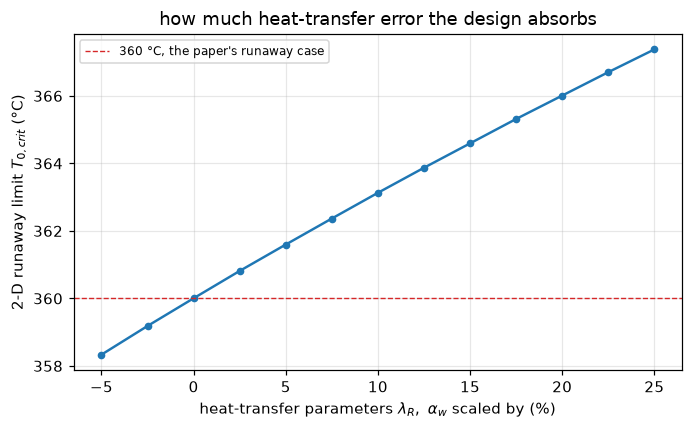

sensitivity near nominal: 0.30 degC of runaway limit per percent of heat-transfer capacity, the quantitative form of the paper's closing warning that prediction 'requires a degree of precision in the measurement of the experimental parameters seldom achieved'. The Pe_mR shift above is 0.14 % of heat-transfer capacity in these units.


77 claims registered


In [17]:
TM357_PE8 = tube2d(357.0, a=(1 / 8.0, CASE.a2)).march(Z_END, cap=CAP_2D).hot_spot()[1]
PE8_TM_SHIFT = abs(TM357_PE8 - TM357) / TM357
print(f"Pe_mR 10 -> 8 at 357 degC: tm_max {TM357:.2f} -> {TM357_PE8:.2f} degC "
      f"({100 * PE8_TM_SHIFT:.1f} %, 'completely negligible', as stated)")
T0C_PE8 = limit_2d(lo=350.0, hi=364.0, a=(1 / 8.0, CASE.a2))
PE8_SHIFT = T0C_2D - T0C_PE8
print(f"and the runaway limit itself, both on n_r = 80 and bisected to 1e-4 degC: {T0C_2D:.4f} "
      f"degC (Pe_mR = 10) vs {T0C_PE8:.4f} degC (Pe_mR = 8), a shift of {PE8_SHIFT:.3f} degC.")

# the heat-transfer margin, drawn as a curve instead of two points
SCALES = np.linspace(0.95, 1.25, 13)


def margin_curve(scale_lam=True, scale_aw=True):
    out = []
    for s in SCALES:
        c = replace(CASE, lam_R=CASE.lam_R * (s if scale_lam else 1.0),
                    alpha_w=CASE.alpha_w * (s if scale_aw else 1.0))
        out.append(limit_2d(lo=355.0, hi=375.0, tol=1e-2, n_r=N_R_SWEEP, case=c))
    return np.array(out)


CRIT_VS_SCALE = margin_curve()
SLOPE = np.polyfit(100 * (SCALES - 1), CRIT_VS_SCALE, 1)[0]
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(100 * (SCALES - 1), CRIT_VS_SCALE, "o-", lw=1.6, ms=4)
ax.axhline(360, color="tab:red", lw=0.9, ls="--", label="360 °C, the paper's runaway case")
ax.set(xlabel=r"heat-transfer parameters $\lambda_R,\ \alpha_w$ scaled by (%)",
       ylabel="2-D runaway limit $T_{0,crit}$ (°C)",
       title="how much heat-transfer error the design absorbs")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"sensitivity near nominal: {SLOPE:.2f} degC of runaway limit per percent of "
      "heat-transfer capacity, the quantitative form of the paper's closing warning that "
      "prediction 'requires a degree of precision in the measurement of the experimental "
      "parameters seldom achieved'. The Pe_mR shift above is "
      f"{PE8_SHIFT / SLOPE:.2f} % of heat-transfer capacity in these units.")

claims.value("pe8_tm357_rel_shift", PE8_TM_SHIFT)
claims.value("pe8_t0crit_shift_C", PE8_SHIFT, rtol=0.02)
claims.value("heat_transfer_slope_C_per_pct", SLOPE, rtol=0.02)
claims.value("ten_percent_limit_shift_C", 10 * SLOPE, rtol=0.02)
claims.value("pe8_shift_over_one_pct", PE8_SHIFT / SLOPE, rtol=0.02)
claims.bound("t0crit_1d_kelvin273_shift_C", T0C_1D_K273 - T0C_1D, min=0.1498, max=0.1502,
             basis="identity", structural=True,
             note="0.15 by construction: the model sees T0 only through T0 + offset, so "
                  "lowering the offset by 0.15 K raises every limit by 0.15 degC; the window "
                  "is the two bisection tolerances")
claims.value("rise363_kelvin273_shift_C", RISE363 - hot_spot_1d(363.0, n_z=2500, case=CASE_K273)[1])

brk("Pe_mR = 5 instead of 8", "pe8_tm357_rel_shift",
    abs(tube2d(357.0, a=(1 / 5.0, CASE.a2)).march(Z_END, cap=CAP_2D).hot_spot()[1] - TM357) / TM357)
brk("Pe_mR = 8 limit on n_r = 48, against the baseline on n_r = 80", "pe8_t0crit_shift_C",
    T0C_2D - _t0c_pe8_48)
_crit_lam_only = margin_curve(scale_aw=False)
_slope_lam = np.polyfit(100 * (SCALES - 1), _crit_lam_only, 1)[0]
brk("only lam_R scaled (alpha_w fixed)", "heat_transfer_slope_C_per_pct", _slope_lam)
brk("only lam_R scaled (alpha_w fixed)", "ten_percent_limit_shift_C", 10 * _slope_lam)
brk("only lam_R scaled (alpha_w fixed)", "pe8_shift_over_one_pct", PE8_SHIFT / _slope_lam)
_case_k2733 = replace(CASE, kelvin=273.3)
brk("offset 273.3 (the convention shift reversed)", "t0crit_1d_kelvin273_shift_C",
    limit_1d(case=_case_k2733) - T0C_1D)
brk("offset 273.3 (the convention shift reversed)", "rise363_kelvin273_shift_C",
    RISE363 - hot_spot_1d(363.0, n_z=2500, case=_case_k2733)[1])

# --- prose numbers, checked against the claims they quote ---------------------------------------
claims.says("29.68", "m_feed_from_composition")              # Parameters
claims.says("0.7", "m_feed_rel_pct")                         # Parameters: "+0.7 %"
claims.says("0.024", "kelvin_offset_rel_T_pct")              # Parameters: "0.024 %"
claims.says("0.5", "k1_shift_kelvin_pct")                    # Parameters: "about 0.5 %"
claims.says("282", "dh3_literal_ratio")                      # thousands separators
claims.says("17.36", "k_printed_series_factor")              # Validation 1
claims.says("360.006", "t0crit_2d_C")                        # Four results
claims.says("0.006", "t0crit_2d_minus_360_C")                # Four results
claims.says("0.043", "pe8_t0crit_shift_C")                   # Four results, What pymrm adds
claims.says("6.6", "z_pa_max_357_m")                         # Four results
claims.says("10%", "pa_shortfall_at_3m_357")                 # Four results
claims.says("3.2", "z_pa_max_360_m")                         # Four results
claims.says("0.3", "heat_transfer_slope_C_per_pct")          # Reuse
claims.says("1.9", "rise363_kelvin273_shift_C")              # Reuse
claims.says("3", "ten_percent_limit_shift_C")                # Reuse: "~3 degC"
claims.says("0.15", "t0crit_1d_kelvin273_shift_C")            # Reuse
claims.says("35", "tm2d_360_lam075_C")                       # What pymrm adds: "about 35"
claims.says("35", "tm2d_360_aw150_C")
print(f"{len(claims.metrics)} claims registered")

In [18]:
BT = pd.DataFrame(BREAK)


def _shown(metric, v):
    # a bound's digits are this run's and differ between machines: shown as such
    if claims.metrics[metric]["kind"] == "bound":
        return f"(here {float(v):.1e})"
    if isinstance(v, (bool, np.bool_)):
        return str(bool(v))
    return f"{v:.4g}"


_table = BT.assign(clean=[_shown(m, v) for m, v in zip(BT.metric, BT.clean)],
                   broken=[_shown(m, v) for m, v in zip(BT.metric, BT.broken)])
with pd.option_context("display.max_colwidth", 60, "display.width", 250,
                       "display.max_rows", 200):
    display(_table[["defect", "metric", "clean", "broken", "caught", "note"]])
_caught = set(BT[BT.caught].metric)
_open = sorted(k for k in claims.metrics if k not in _caught)
print(f"{len(BT)} rows; {int(BT.caught.sum())} fail the claim they target, "
      f"{len(BT) - int(BT.caught.sum())} do not (each says why in its note).")
print(f"{len(_caught)} of {len(claims.metrics)} claims are failed by at least one row.")
print("claims with no failing row:", ", ".join(_open) or "none")

,defect,metric,clean,broken,caught,note
0,G read literally as 4.684,pehr_identity_rel,0.001279,0.999,True,
1,G read literally as 4.684,re_from_G,125.4,0.1254,True,
2,tube radius R' taken as the diameter,u_ref_identity_rel,0.002883,0.2799,True,
3,tube radius R' taken as the diameter,u_lam075_identity_rel,0.0001244,0.2639,True,
4,tube radius R' taken as the diameter,u_aw150_identity_rel,0.002894,0.2896,True,
5,"44 read as mol/m3, not g/Nm3",na0_from_44gnm3_rel,0.005249,105.7,True,
6,air molar mass taken as N2's (28.01),m_feed_from_composition,29.68,28.73,True,
7,air molar mass taken as N2's (28.01),m_feed_rel_pct,0.6897,-2.537,True,
8,D2.2's volumetric c_p 0.323 taken as mass basis,adiabatic_rise_AB_C,384.9,297.9,True,
9,-dH1 compared in kcal/kmol with dH3 in kcal/gmol,dh3_literal_ratio,281.7,2.817e+05,True,


94 rows; 83 fail the claim they target, 11 do not (each says why in its note).
77 of 77 claims are failed by at least one row.
claims with no failing row: none


### What the checks can and cannot do

- The exchanger claims test the radial operator against the paper's exact
  series, so every assembly defect that matters (wrong `nu`, a flipped wall
  sign) moves them. They test nothing in the kinetics.
- The stated-result claims compare with Froment's own computation. A shared
  transcription error in $k_2$ or $k_3$ would move them, which is why the
  $k_2 \leftrightarrow k_3$ rows are there; an error both this page and the
  paper made cannot be seen.
- The second routes share only the printed constants. They can tell a wrong
  operator or integrator from a right one, not a wrong constant from a right
  one.
- The labels (does 360 °C run away, is the 1-D limit inside its bracket)
  carry their margins, so a label that sits inside the numerical noise of its
  threshold would raise rather than print.

## Reuse

| Change | Where |
|---|---|
| Other kinetics in a fixed-bed tube | write a pointwise `source(u)` for state `(n_r, n_f)` and pass it to `model.Tube2D` / `model.Tube1D`; `NumJac` takes its Jacobian |
| More species or a second temperature | one more field: one more entry in `dispersion` and `wall` |
| A coolant temperature other than the inlet's, constant along the tube | `u_wall=` (the wall condition becomes `dt/dr = -alpha (t - t_wall)`) |
| A steady 1-D formulation | `model.Tube1DSteady` (upwind finite volumes, `pymrm.newton`) |
| A runaway or ignition threshold | `model.critical_inlet` with a predicate that marches from the inlet; it checks both bracket ends |

**What `Tube2D` assumes**, and so what a new use must also satisfy: plug flow
with the same unit convective coefficient for every field (the equations
divided through by the convective term, as in Froment's dimensionless form);
no axial dispersion; dispersion and wall coefficients constant in $r$ and
$z$; a coolant value constant along the tube (it is folded into a constant
boundary vector when the operators are assembled); a uniform radial grid. A
velocity profile, temperature-dependent properties or a coolant that heats
up along the tube need changes to the class, not only a new source.

- **The 1-D runaway machinery** with criteria instead of brute force is the
  sibling page [`D2.2`](../D2.2-van-welsenaere-froment-runaway/): same
  reactor, same $k_1$, closed-form critical-inlet criteria.
- **The S6 radial-operator pattern** (cylindrical `construct_grad`/
  `construct_div`, Robin wall) is shared with
  [`A2.3`](../A2.3-taylor-aris-dispersion/) (dispersion closure) and
  [`A3.15`](../A3.15-graetz-nusselt/) (Graetz problem); the radial
  heat-transfer parameters themselves are
  [`A3.12`](../A3.12-yagi-kunii-effective-conductivity/) (Yagi–Kunii, the very
  correlation Froment used for $\lambda_R$).
- **Froment kinetics with data** is
  [`C2.1`](../C2.1-xu-froment-smr/) (Xu & Froment SMR, validated against the
  runs it was fitted to); use it as the model when a kinetics page proper is
  wanted.

**Limits to keep in mind.** The kinetics are pseudo-first-order effective rate
laws at 1 atm in large air excess on a 1960s V₂O₅ catalyst, asserted by the
paper as representative and never fitted to data in this document; do not
transplant them quantitatively. The runaway limit is exponentially sensitive:
this page measures 0.3 °C of limit per percent of heat-transfer capacity (so
the paper's own 10 % parameter uncertainty is worth about 3 °C), and even the
unprinted 273-vs-273.15 Kelvin convention, 0.5 % in $k_1$, moves every
limit by exactly 0.15 °C (the model sees only $T_0$ plus the offset) and the
363 °C hot spot by 1.9 °C. Any reuse of the *numbers* (rather than the pattern)
inherits that sensitivity. The paper's own kinetics were superseded by
Calderbank's measurements (not on disk) and by Froment & Bischoff's textbook
treatment; a separate `D3.4` page against those sources would be validation,
this page is reproduction.

**Reference.** Froment, G. F. (1967). Industrial & Engineering Chemistry
**59**(2), 18–27. [doi:10.1021/ie50686a006](https://doi.org/10.1021/ie50686a006)

In [19]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C2.10:
  pehr_identity_rel             = 0.0012793        value  rtol 0.05
  u_ref_identity_rel            = 0.0028835        value  rtol 0.05
  u_lam075_identity_rel         = 0.00012436       value  rtol 0.05
  u_aw150_identity_rel          = 0.0028939        value  rtol 0.05
  na0_from_44gnm3_rel           = 0.0052487        value  rtol 0.05
  re_from_G                     = 125.35           value  rtol 0.05
  m_feed_from_composition       = 29.683           value  rtol 0.001
  m_feed_rel_pct                = 0.68972          value  rtol 0.05
  adiabatic_rise_AB_C           = 384.9            value  rtol 0.05
  dh3_literal_ratio             = 281.65           value  rtol 0.05
  kelvin_offset_rel_T_pct       = 0.023804         value  rtol 0.05
  k1_shift_kelvin_pct           = 0.51669          value  rtol 0.05
  d22_shared_max_rel            = (here 2.7e-05)   bound  bound <= 0.001 [chosen]
  d22_gcp_rel                   = 0.0070519        value  rtol 0.05
  hx_series_rel